# Land Use and Land Cover Classification Using Convolutional Neural Networks

**Student:** Tumisi Vinton Mosoeu  
**Student Number:** ST10356048  
**Module:** Programming for Data Analytics 2 (PDAN8412/w)  
**Assessment:** Portfolio of Evidence – Part 3  
**Dataset:** EuroSAT RGB  
**Technologies:** Python, Apache Spark, TensorFlow and Keras

---

## 1. Introduction

Satellite images contain useful information about how land is used and what covers it. For example, a photograph taken from above might show a forest, a residential area, farmland or a river.

In this project, I explore how a Convolutional Neural Network (CNN) can learn to recognise these differences.

I'll use the EuroSAT RGB dataset, which contains 27,000 labelled satellite images across ten land-use and land-cover categories.

My approach is to understand the data before building the model. I'll begin by checking the quality and characteristics of the images using Python and Apache Spark. What I learn from this analysis will guide how I prepare the images, design the CNN and evaluate its performance.

The aim is not simply to achieve a high accuracy score. I also want to understand which categories the model recognises well, where it makes mistakes and whether reasonable improvements can help it perform better.

## 2. Dataset Evaluation and Justification

### 2.1 Dataset Background

For this project, I selected the EuroSAT RGB dataset, developed by Helber et al. (2019) using satellite imagery from the European Space Agency's Sentinel-2 programme.

According to Helber et al. (2019), EuroSAT contains 27,000 labelled images representing ten land-use and land-cover categories, including forests, rivers, agricultural land and residential areas.

I chose the RGB version because its relatively small images (64 × 64 pixels) make it practical to train and evaluate a CNN without placing unnecessary demands on my computer.

### 2.2 Why EuroSAT Is Suitable

EuroSAT is suitable for this investigation because it provides labelled images for a supervised, multiclass classification problem.

LeCun, Bengio and Hinton (2015) explain that deep learning models can learn increasingly complex representations of data through multiple processing layers. In image classification, CNNs are particularly useful because they learn visual features while retaining important spatial relationships.

This makes a CNN a reasonable choice for distinguishing between the different land-cover categories in EuroSAT.

The dataset also exceeds the assignment's minimum requirement of 10,000 images, leaving enough examples for training, validation and testing.

Another advantage is that EuroSAT is publicly available and supported by published research, making it suitable for a reproducible investigation (Helber et al., 2019).

### 2.3 Data Quality and Potential Challenges

My initial checks confirmed that the dataset contains all 27,000 expected images. Every image is stored in JPEG format, measures 64 × 64 pixels and passed the initial file-integrity check.

However, the categories are not perfectly balanced. Their sizes range from 2,000 to 3,000 images, meaning the largest categories contain 50% more examples than the smallest.

Although this imbalance is relatively modest, I will account for it when splitting the data and evaluating the CNN.

There are also several potential challenges worth considering:

- **Visual similarities:** Agricultural and vegetation categories may share colours, textures and spatial patterns.
- **Duplicate images:** Identical or nearly identical images could make evaluation results misleading if related examples appear in different data partitions.
- **Geographical similarity:** Images from nearby locations may contain related visual features, potentially making random splitting overly optimistic.
- **Limited image detail:** The 64 × 64 resolution keeps training manageable but may make subtle differences between categories harder to recognise.

I will investigate these issues where the available data allows, rather than assuming that the dataset is completely clean.

### 2.4 Suitability for the Project

Overall, EuroSAT provides a suitable starting point for developing and evaluating a multiclass CNN.

Although the publisher's broader interest is premises security, the assignment allows an image-recognition model that does not involve facial recognition.

This project will therefore focus on satellite land-cover classification as a practical demonstration of CNN-based image recognition.

The findings may help explain the capabilities and limitations of CNNs, but they should not be treated as evidence that the resulting model is suitable for real-world security applications.

## 3. Analysis Plan

Before developing the CNN, I need a clear plan for investigating the images, preparing the data and measuring the model's performance.

I want each decision to have a reason behind it. Rather than applying techniques simply because they are commonly used, I'll use the dataset findings to guide the modelling process.

### 3.1 Exploratory Data Analysis

I'll begin by examining the dataset's structure, quality and visual characteristics using Python and Apache Spark.

My investigation will focus on:

- **Class distribution:** Check whether certain categories contain considerably more images than others.
- **Image quality:** Verify image dimensions, formats and readability.
- **Visual inspection:** Compare examples from all ten categories to identify visible similarities and differences.
- **Colour characteristics:** Investigate RGB values, brightness and contrast across categories.
- **Duplicate detection:** Identify exact duplicate files that could affect model evaluation and acknowledge the remaining risk of visually similar images.

I will also consider whether related satellite images could affect the reliability of random data splitting.

The aim is to identify patterns and potential problems before training the CNN, then use those findings to justify my modelling decisions.

### 3.2 Feature Selection and Image Preparation

Unlike traditional machine-learning models, CNNs can learn useful image features directly from pixel data.

LeCun, Bengio and Hinton (2015) explain that deep learning models develop increasingly complex representations through successive processing layers. This supports using convolutional layers to learn visual patterns rather than manually selecting individual pixel features.

My image preparation will include:

- Retaining the original 64 × 64 RGB dimensions if the quality checks confirm they are consistent.
- Scaling pixel values to a common numerical range.
- Creating reproducible, stratified training, validation and test partitions.
- Checking for duplicate images and potential data leakage before training.
- Considering suitable image augmentation if the EDA and model results suggest it could improve generalisation.

I'll use fixed random seeds and save the data partitions so that the same images can be used in subsequent experiments.

### 3.3 CNN Development and Training

I'll begin with a relatively small CNN using TensorFlow and Keras.

The model will use convolutional layers to learn visual features, pooling layers to reduce feature-map dimensions and a final classification layer to predict one of the ten categories.

My initial training settings will be:

| Parameter | Initial choice | Reason |
|---|---|---|
| Input size | 64 × 64 × 3 | Preserve the original RGB image dimensions. |
| Output classes | 10 | Match the ten EuroSAT categories. |
| Optimiser | Adam | Provide an adaptive approach to updating model weights. |
| Learning rate | 0.001 | Establish a practical starting point for training. |
| Loss function | Sparse categorical cross-entropy | Suitable for multiclass classification with integer labels. |
| Batch size | 32 | Balance memory use and training efficiency. |
| Maximum epochs | 15 | Allow learning while keeping the experiment manageable. |
| Early stopping | Enabled | Reduce unnecessary training when validation loss stops improving. |

These settings are starting choices, not guaranteed optimal values.

I'll first examine the baseline model's training and validation results before deciding whether any improvements are justified.

### 3.4 Model Evaluation and Improvement

I'll evaluate the CNN using several measures because overall accuracy may hide weaker performance on individual categories.

The evaluation will include:

- **Accuracy:** The proportion of images classified correctly.
- **Precision:** How reliable predictions are for each category.
- **Recall:** How many actual images from each category the model recognises.
- **F1-score:** A measure that balances precision and recall.
- **Confusion matrix:** A breakdown of the categories the model predicts correctly and incorrectly.

I'll also examine training and validation curves to identify possible overfitting or underfitting.

If the baseline model shows weaknesses, I'll investigate a small number of justified improvements.

Shorten and Khoshgoftaar (2019) explain that image augmentation can introduce useful variation into training data and may help reduce overfitting. This makes augmentation a reasonable option to investigate, particularly if the CNN struggles to generalise beyond its training images.

I'll compare any improved model with the baseline using the same validation data and selection criterion.

The test set will remain untouched until I have selected the final model.

### 3.5 Reporting the Findings

Finally, I'll prepare a concise PDF report explaining the investigation and its results.

The report will cover the dataset, important EDA findings, image preparation, CNN development, model evaluation and any improvements made.

I'll also discuss the model's limitations and what the results suggest about CNN-based image classification.

The notebook will contain the detailed code and supporting evidence, while the report will focus on the most important findings and conclusions.

### 3.6 Reproducibility and Computational Efficiency

Throughout the project, I'll use project-relative file paths, fixed random seeds and documented software versions.

I'll save the data partitions, class mapping, model checkpoints and training histories so that the experiments can be examined and repeated.

To reduce unnecessary computation, I'll preserve the original image resolution, use efficient TensorFlow data pipelines and begin with a compact CNN before considering improvements.

I recognise that different computers or software environments may produce slightly different training results, even when random seeds are fixed.

My goal is therefore to make the methodology transparent and repeatable without introducing unnecessary complexity.

## 4. Preparing the Working Environment

I'll use Python for the analysis, Apache Spark to explore the dataset and TensorFlow/Keras to build the CNN.

Before working with the images, I want to check that the main libraries are available and record their versions.

This will also make it easier for someone else to reproduce the project using a similar environment.

In [2]:
# Libraries for file handling and checking the environment
import sys
import platform
from pathlib import Path

# Libraries for working with and visualising data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Libraries for image classification and Spark analysis
import tensorflow as tf
import pyspark

# Check the versions used in this notebook
print("Python:", sys.version.split()[0])
print("Operating system:", platform.system())
print("TensorFlow:", tf.__version__)
print("PySpark:", pyspark.__version__)
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)

Python: 3.12.16
Operating system: Windows
TensorFlow: 2.21.0
PySpark: 4.2.0
pandas: 2.3.3
NumPy: 2.5.5


## 5. Organising the Project Files

I want this notebook to work on another computer without anyone having to change file paths.

Instead of referring to folders on my own computer, I'll locate the main project directory and use it to find the dataset and save the results.

This also helps me keep the original images separate from any processed data, figures and trained models.

In [4]:
# Find the project folder from the current working directory.
current_folder = Path.cwd().resolve()

if (current_folder / "notebooks").is_dir():
    project_folder = current_folder

elif current_folder.name == "notebooks":
    project_folder = current_folder.parent

else:
    raise FileNotFoundError(
        "Project folder not found. Open JupyterLab from the project directory."
    )

# Define the folders we will use.
raw_folder = project_folder / "data" / "raw"
processed_folder = project_folder / "data" / "processed"
figures_folder = project_folder / "figures"
models_folder = project_folder / "models"
reports_folder = project_folder / "reports"

# Create any missing folders.
for folder in [raw_folder, processed_folder, figures_folder,
               models_folder, reports_folder]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory found successfully.")
print("Raw data folder:", raw_folder.relative_to(project_folder))

Project directory found successfully.
Raw data folder: data\raw


## 6. Obtaining the EuroSAT Dataset

I selected EuroSAT RGB because it provides a manageable collection of labelled satellite images for a multiclass classification problem.

The images were originally developed from Sentinel-2 satellite observations and organised into ten land-use and land-cover categories.

I obtained the RGB dataset from the official Zenodo repository linked by its researchers.

Before using the images, I'll check that the downloaded archive is available and inspect how the files are organised. This will help me confirm that I'm working with the expected data before moving on to the analysis.

**Dataset source:** https://zenodo.org/records/7711810

In [5]:
# Find the original EuroSAT archive.
dataset_zip = raw_folder / "EuroSAT_RGB.zip"

# Check that the file is available before continuing.
if dataset_zip.is_file():

    size_mb = dataset_zip.stat().st_size / (1024 ** 2)

    print("EuroSAT archive found.")
    print(f"Archive size: {size_mb:.2f} MiB")

else:

    raise FileNotFoundError(
        "EuroSAT_RGB.zip is missing from data/raw/. "
        "Download the RGB archive from the official Zenodo repository."
    )

EuroSAT archive found.
Archive size: 90.27 MiB


### Checking the Download

Finding the ZIP file is a good start, but I also want to make sure it can be opened properly.

I'll check the archive for damaged files before extracting the images. This is a simple way to avoid working with an incomplete download.

In [6]:
import zipfile

# Open the archive and check for damaged files.
with zipfile.ZipFile(dataset_zip, "r") as archive:

    damaged_file = archive.testzip()

    image_files = [
        name for name in archive.namelist()
        if name.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

print("Images found in archive:", f"{len(image_files):,}")

if damaged_file is None:
    print("ZIP integrity check passed.")
else:
    raise ValueError(f"Damaged file found: {damaged_file}")

Images found in archive: 27,000
ZIP integrity check passed.


### Extracting the Images

Now that the archive has passed the initial checks, I'll extract the images into the raw data folder.

I'll keep the original ZIP file unchanged so that I still have a copy of the dataset as it was downloaded.

Once extracted, the images should be organised into folders representing the different categories.

In [7]:
# Extract the dataset into the raw data directory.
# We check first to avoid repeating the extraction unnecessarily.

extracted_folder = raw_folder / "EuroSAT_RGB"

if not extracted_folder.exists():

    with zipfile.ZipFile(dataset_zip, "r") as archive:
        archive.extractall(raw_folder)

    print("Dataset extracted successfully.")

else:
    print("An extracted dataset folder already exists.")

Dataset extracted successfully.


### Looking at the Folder Structure

The next step is to see how the extracted images are organised.

I expect to find folders representing the ten categories. Checking this now will help me understand how the labels are stored and how I can load the images for analysis.

In [8]:
# Show the folders and files in the raw data directory.

print("Contents of data/raw/:\n")

for item in sorted(raw_folder.iterdir()):
    print(item.name)

# Look one level deeper if the extracted folder exists.
if extracted_folder.is_dir():

    print("\nContents of the extracted folder:\n")

    for item in sorted(extracted_folder.iterdir()):
        print(item.name)

Contents of data/raw/:

EuroSAT_RGB
EuroSAT_RGB.zip

Contents of the extracted folder:

AnnualCrop
Forest
HerbaceousVegetation
Highway
Industrial
Pasture
PermanentCrop
Residential
River
SeaLake


### Initial Findings

The initial checks confirm that the EuroSAT RGB archive is available and that its contents can be read successfully.

The images are organised into ten category folders, giving me a straightforward way to identify their labels for multiclass classification.

These checks provide a useful starting point, but they do not tell me everything about the quality of the data. I still need to examine the number of images in each category, inspect the image dimensions and look for possible problems such as duplicates or unreadable files.

Those findings will help me decide how to prepare the data before training the CNN.

## 7. Exploratory Data Analysis

Now that I've confirmed the images are available and readable, I want to explore their characteristics before training the CNN.

I'll use Python and Apache Spark to investigate the class distribution, visual patterns, colour characteristics and potential data-quality issues. My aim is to understand what makes the categories different, where they overlap and whether anything in the dataset could affect the model's performance.

I'll use these findings to guide image preparation, model training and evaluation rather than making decisions based on assumptions.

### 7.1 Dataset Inventory and Class Distribution

I'll begin by creating an inventory containing each image's filename, category and relative file path.

I'll save this information as a CSV file and load it into Apache Spark. According to the Apache Software Foundation (2026), Spark DataFrames support operations such as grouping, filtering and aggregation, making them useful for examining patterns in structured data.

By working with image metadata rather than loading the image pixels into Spark, I can investigate the dataset efficiently without unnecessary processing.

I'll start by checking the number of images in each category. This will help me assess the class distribution and decide whether any precautions are needed when splitting the dataset for CNN training.

In [11]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

# Start Spark locally without using unnecessary resources.
spark = (
    SparkSession.builder
    .appName("EuroSAT_EDA")
    .master("local[2]")
    .config("spark.sql.shuffle.partitions", "4")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

print(f"Spark version: {spark.version}")
print("Spark is ready for analysis.")

Spark version: 4.2.0
Spark is ready for analysis.


In [13]:
import csv

# Build a simple inventory of the images.
image_records = []

for folder in class_folders:
    for image_path in sorted(folder.glob("*.jpg")):
        image_records.append((
            image_path.name,
            folder.name,
            image_path.relative_to(project_folder).as_posix()
        ))

# Save the inventory so Spark can read it directly.
inventory_file = processed_folder / "eurosat_inventory.csv"

with open(inventory_file, "w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)

    writer.writerow(["filename", "category", "image_path"])
    writer.writerows(image_records)

print(f"Images found: {len(image_records):,}")
print("Inventory saved to:", inventory_file.relative_to(project_folder))

# Let Spark load the inventory from the CSV file.
image_df = (
    spark.read
    .option("header", True)
    .csv(str(inventory_file))
)

print(f"\nImages loaded into Spark: {image_df.count():,}")

image_df.show(5, truncate=False)

Images found: 27,000
Inventory saved to: data\processed\eurosat_inventory.csv

Images loaded into Spark: 27,000
+-------------------+----------+---------------------------------------------------+
|filename           |category  |image_path                                         |
+-------------------+----------+---------------------------------------------------+
|AnnualCrop_1.jpg   |AnnualCrop|data/raw/EuroSAT_RGB/AnnualCrop/AnnualCrop_1.jpg   |
|AnnualCrop_10.jpg  |AnnualCrop|data/raw/EuroSAT_RGB/AnnualCrop/AnnualCrop_10.jpg  |
|AnnualCrop_100.jpg |AnnualCrop|data/raw/EuroSAT_RGB/AnnualCrop/AnnualCrop_100.jpg |
|AnnualCrop_1000.jpg|AnnualCrop|data/raw/EuroSAT_RGB/AnnualCrop/AnnualCrop_1000.jpg|
|AnnualCrop_1001.jpg|AnnualCrop|data/raw/EuroSAT_RGB/AnnualCrop/AnnualCrop_1001.jpg|
+-------------------+----------+---------------------------------------------------+
only showing top 5 rows


In [14]:
# Count the images in each category using Spark.
class_distribution = (
    image_df
    .groupBy("category")
    .agg(F.count("*").alias("images"))
    .orderBy("category")
)

class_distribution.show(truncate=False)

+--------------------+------+
|category            |images|
+--------------------+------+
|AnnualCrop          |3000  |
|Forest              |3000  |
|HerbaceousVegetation|3000  |
|Highway             |2500  |
|Industrial          |2500  |
|Pasture             |2000  |
|PermanentCrop       |2500  |
|Residential         |3000  |
|River               |2500  |
|SeaLake             |3000  |
+--------------------+------+



,category,images,percentage
0,AnnualCrop,3000,11.11
1,Forest,3000,11.11
2,HerbaceousVegetation,3000,11.11
3,Highway,2500,9.26
4,Industrial,2500,9.26
5,Pasture,2000,7.41
6,PermanentCrop,2500,9.26
7,Residential,3000,11.11
8,River,2500,9.26
9,SeaLake,3000,11.11


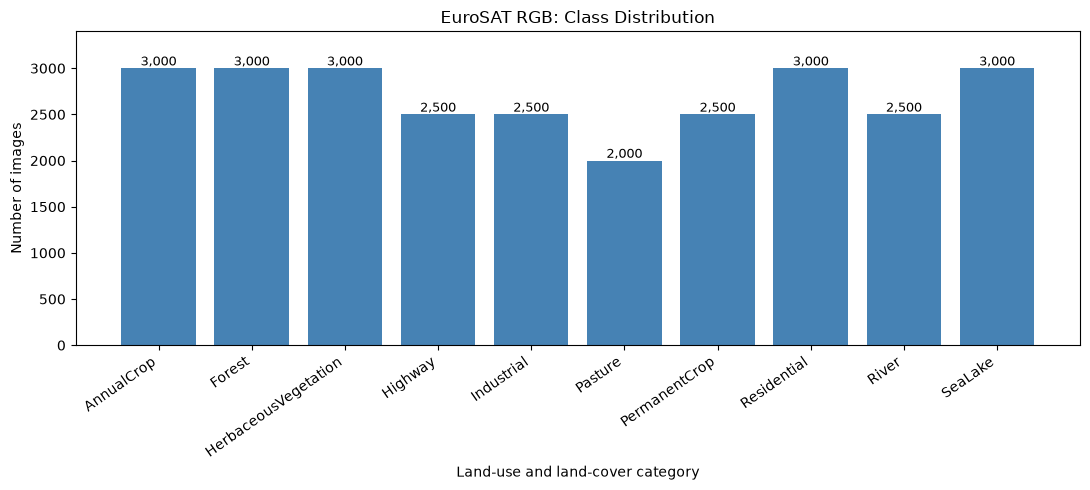

In [15]:
# Convert only the ten summary rows to pandas for plotting.
class_results = class_distribution.toPandas()

# Calculate the percentage of images in each category.
class_results["percentage"] = (
    class_results["images"] / class_results["images"].sum() * 100
).round(2)

display(class_results)

# Plot the class distribution.
plt.figure(figsize=(11, 5))

bars = plt.bar(
    class_results["category"],
    class_results["images"],
    color="steelblue"
)

plt.title("EuroSAT RGB: Class Distribution")
plt.xlabel("Land-use and land-cover category")
plt.ylabel("Number of images")

plt.xticks(rotation=35, ha="right")

# Display the counts above each bar.
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 30,
        f"{int(height):,}",
        ha="center",
        fontsize=9
    )

plt.ylim(0, 3400)
plt.tight_layout()

# Save the chart for the final report.
plt.savefig(
    figures_folder / "class_distribution.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

#### What the Class Distribution Revealed

Spark confirmed that all 27,000 images are represented across the ten categories. The class sizes range from 2,000 images for Pasture to 3,000 for the largest categories.

This gives the dataset a largest-to-smallest class ratio of 1.5:1. The imbalance is not particularly severe, but it is still worth considering when preparing the data.

I'll use a stratified split so that each category is represented proportionally in the training, validation and test sets. During evaluation, I'll also examine the precision, recall and F1-score for individual categories.

This will help me assess whether the CNN performs consistently across the dataset, rather than relying only on overall accuracy.

### 7.2 Visual Inspection of the Images

The class distribution tells me how many images are available, but it doesn't show what makes the categories different.

I'll examine a few examples from each category to see how their colours, textures and visible patterns compare.

I'm particularly interested in categories that look similar, because those differences may be difficult for the CNN to learn. I'll return to these observations when interpreting the model's confusion matrix.

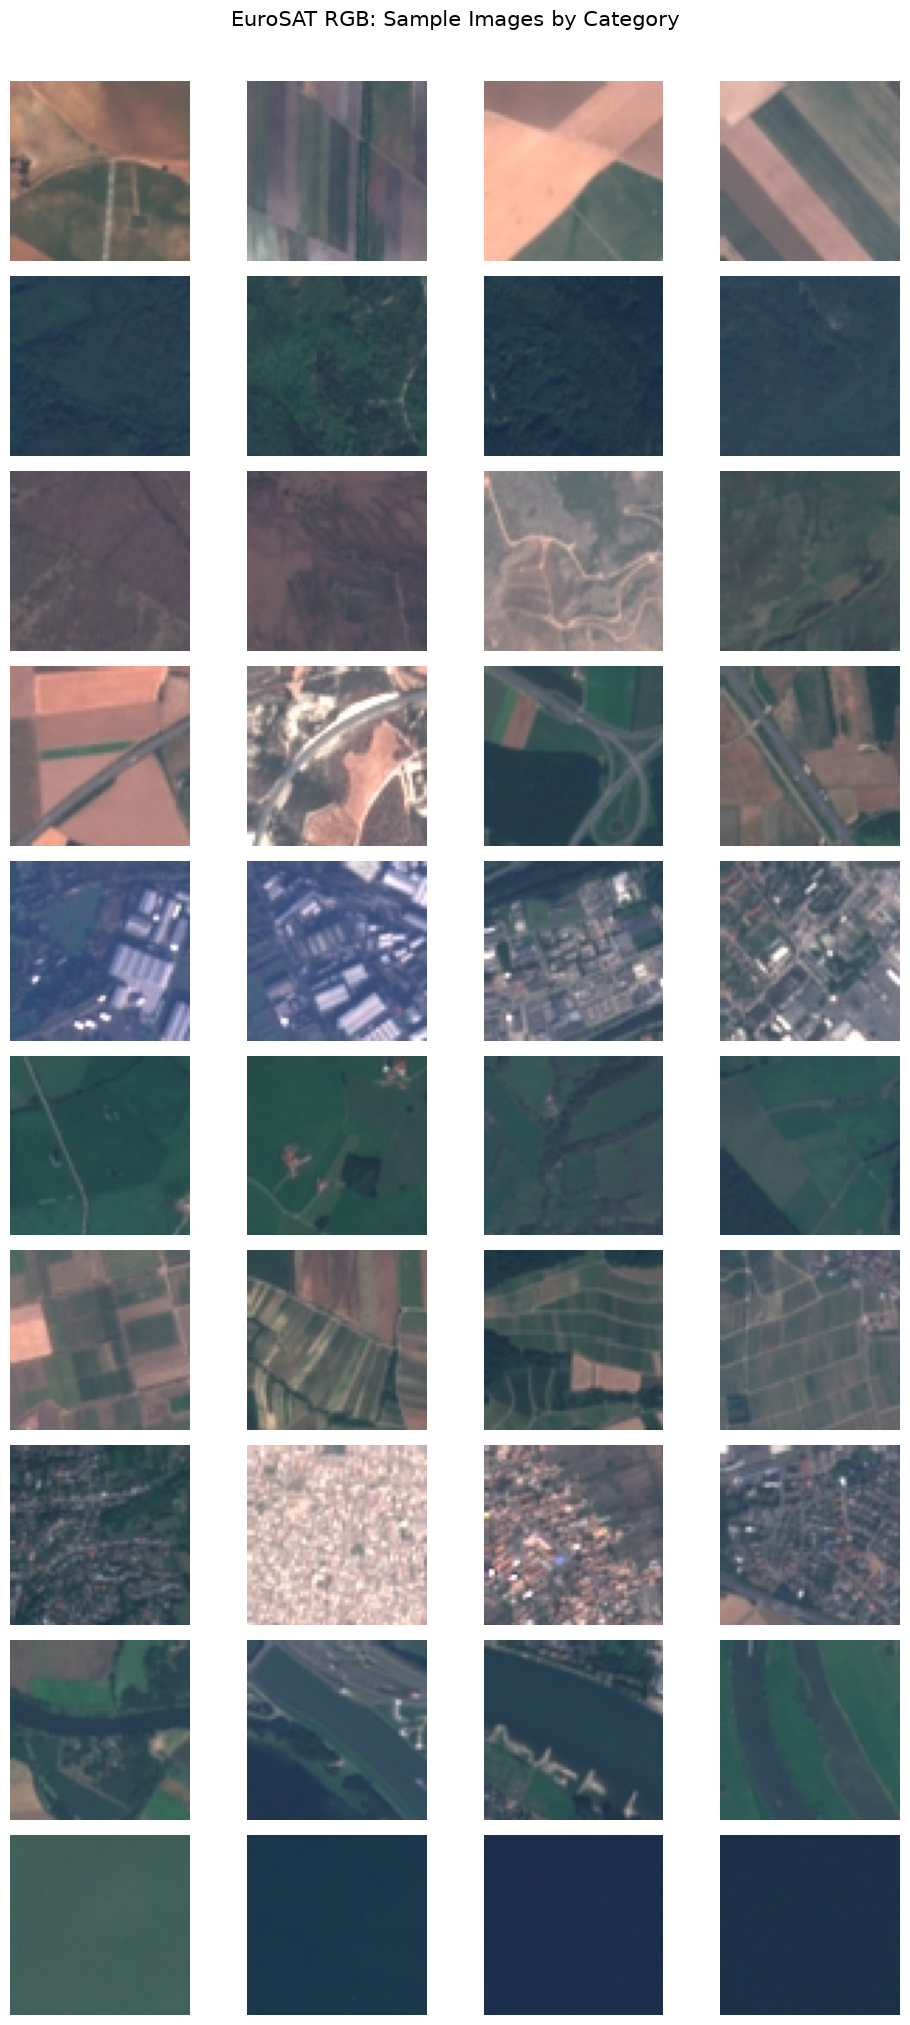

In [16]:
from PIL import Image

# Use a fixed seed for reproducible sample selection.
rng = np.random.default_rng(42)

# Display four images from each of the ten categories.
fig, axes = plt.subplots(
    nrows=10,
    ncols=4,
    figsize=(10, 20)
)

for row, folder in enumerate(class_folders):

    image_paths = sorted(folder.glob("*.jpg"))

    # Select four different images from the category.
    selected_images = rng.choice(
        image_paths,
        size=4,
        replace=False
    )

    for col, image_path in enumerate(selected_images):

        with Image.open(image_path) as image:
            axes[row, col].imshow(image.convert("RGB"))

        axes[row, col].axis("off")

        # Add the category name beside the first image.
        if col == 0:
            axes[row, col].set_ylabel(
                folder.name,
                rotation=0,
                ha="right",
                va="center",
                fontsize=10,
                labelpad=15
            )

plt.suptitle(
    "EuroSAT RGB: Sample Images by Category",
    fontsize=15,
    y=1.01
)

plt.tight_layout()

plt.savefig(
    figures_folder / "sample_images_by_category.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

#### What the Visual Inspection Revealed

The sample images show that the categories differ in more than just colour. Highways have recognisable road patterns, residential areas contain dense arrangements of buildings, and permanent crops often show repeated planting patterns. These are the kinds of spatial features that a CNN should be able to learn.

I also noticed some similarities between categories. AnnualCrop and PermanentCrop both contain agricultural fields, while Forest, Pasture and HerbaceousVegetation share certain vegetation characteristics. This could make some classes more difficult to distinguish.

Another interesting observation is that images within the same category are not always alike. The Highway examples, for instance, range from simple roads to more complicated intersections.

These findings support keeping all three RGB channels and using a CNN that can learn both colour and spatial patterns. Later, I'll use the confusion matrix to investigate whether the visually similar categories are also the ones the model struggles to classify.

### 7.3 Colour, Brightness and Contrast Analysis

Looking at the sample images gave me an idea of how the categories differ, but I only examined a small part of the dataset.

I'll now calculate some basic image statistics for all 27,000 images. These include average RGB values, brightness and contrast.

I want to see whether the categories have noticeably different colour characteristics and how much the images vary within each category.

These findings may help me decide whether additional image preprocessing or augmentation would be useful.

In [17]:
import csv
from PIL import Image

# Save the calculated statistics in the processed data folder.
statistics_file = processed_folder / "eurosat_image_statistics.csv"

with open(statistics_file, "w", newline="", encoding="utf-8") as file:

    writer = csv.writer(file)

    writer.writerow([
        "filename",
        "category",
        "image_path",
        "mean_red",
        "mean_green",
        "mean_blue",
        "brightness",
        "contrast"
    ])

    # Process the images one at a time.
    for folder in class_folders:

        for image_path in sorted(folder.glob("*.jpg")):

            with Image.open(image_path) as image:

                rgb = np.asarray(
                    image.convert("RGB"),
                    dtype=np.float32
                )

                # Calculate the average value of each colour channel.
                mean_rgb = rgb.mean(axis=(0, 1))

                # Calculate approximate grayscale brightness.
                grayscale = (
                    0.299 * rgb[:, :, 0]
                    + 0.587 * rgb[:, :, 1]
                    + 0.114 * rgb[:, :, 2]
                )

                brightness = grayscale.mean()
                contrast = grayscale.std()

            writer.writerow([
                image_path.name,
                folder.name,
                image_path.relative_to(project_folder).as_posix(),
                float(mean_rgb[0]),
                float(mean_rgb[1]),
                float(mean_rgb[2]),
                float(brightness),
                float(contrast)
            ])

print("Image statistics saved successfully.")
print("File:", statistics_file.relative_to(project_folder))

Image statistics saved successfully.
File: data\processed\eurosat_image_statistics.csv


In [18]:
# Load image statistics using Spark's CSV reader.
stats_df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(str(statistics_file))
)

print(f"Images analysed: {stats_df.count():,}")

stats_df.printSchema()

Images analysed: 27,000
root
 |-- filename: string (nullable = true)
 |-- category: string (nullable = true)
 |-- image_path: string (nullable = true)
 |-- mean_red: double (nullable = true)
 |-- mean_green: double (nullable = true)
 |-- mean_blue: double (nullable = true)
 |-- brightness: double (nullable = true)
 |-- contrast: double (nullable = true)



In [19]:
# Calculate average image characteristics for each category.
category_stats = (
    stats_df
    .groupBy("category")
    .agg(
        F.round(F.avg("mean_red"), 2).alias("red"),
        F.round(F.avg("mean_green"), 2).alias("green"),
        F.round(F.avg("mean_blue"), 2).alias("blue"),
        F.round(F.avg("brightness"), 2).alias("brightness"),
        F.round(F.avg("contrast"), 2).alias("contrast")
    )
    .orderBy("category")
)

category_stats.show(truncate=False)

+--------------------+------+------+------+----------+--------+
|category            |red   |green |blue  |brightness|contrast|
+--------------------+------+------+------+----------+--------+
|AnnualCrop          |129.6 |120.02|117.17|122.56    |25.34   |
|Forest              |39.36 |64.46 |75.96 |58.26     |3.83    |
|HerbaceousVegetation|98.15 |98.75 |103.94|99.16     |15.76   |
|Highway             |88.03 |96.68 |103.39|94.86     |21.98   |
|Industrial          |123.38|125.41|134.35|125.82    |41.65   |
|Pasture             |61.92 |88.45 |94.16 |81.17     |9.62    |
|PermanentCrop       |122.11|116.02|114.04|117.62    |22.1    |
|Residential         |100.06|103.79|113.02|103.72    |20.72   |
|River               |67.04 |86.62 |96.9  |81.93     |19.2    |
|SeaLake             |48.1  |72.84 |89.07 |67.29     |2.89    |
+--------------------+------+------+------+----------+--------+



#### What the Image Statistics Revealed

The Spark analysis shows noticeable differences in brightness and contrast between categories. Industrial images have the highest average brightness (125.82) and contrast (41.65), while Forest and SeaLake are considerably darker and have much lower contrast.

Some categories also have similar characteristics. AnnualCrop and PermanentCrop have fairly close average brightness values, while Forest and SeaLake both have relatively low contrast despite representing different types of land cover.

These results support what I noticed during the visual inspection: colour and brightness provide useful information, but they are unlikely to be enough to distinguish every category.

I'll retain all three RGB channels and normalise pixel values before training. I'll also consider testing modest image augmentation, but only keep it if the validation results show that it improves the model's ability to generalise.

I still need to investigate how much these values vary within each category. Averages alone can hide important differences between individual images.

### Investigating Variation Within Categories

The category averages reveal some useful differences, but they do not tell me whether individual images within each category are similar.

For example, two categories might have nearly identical average brightness while containing very different ranges of images.

I'll use boxplots to examine how brightness and contrast vary within each category. This should give me a more complete picture of the dataset and help me decide whether the differences are meaningful enough to influence preprocessing.

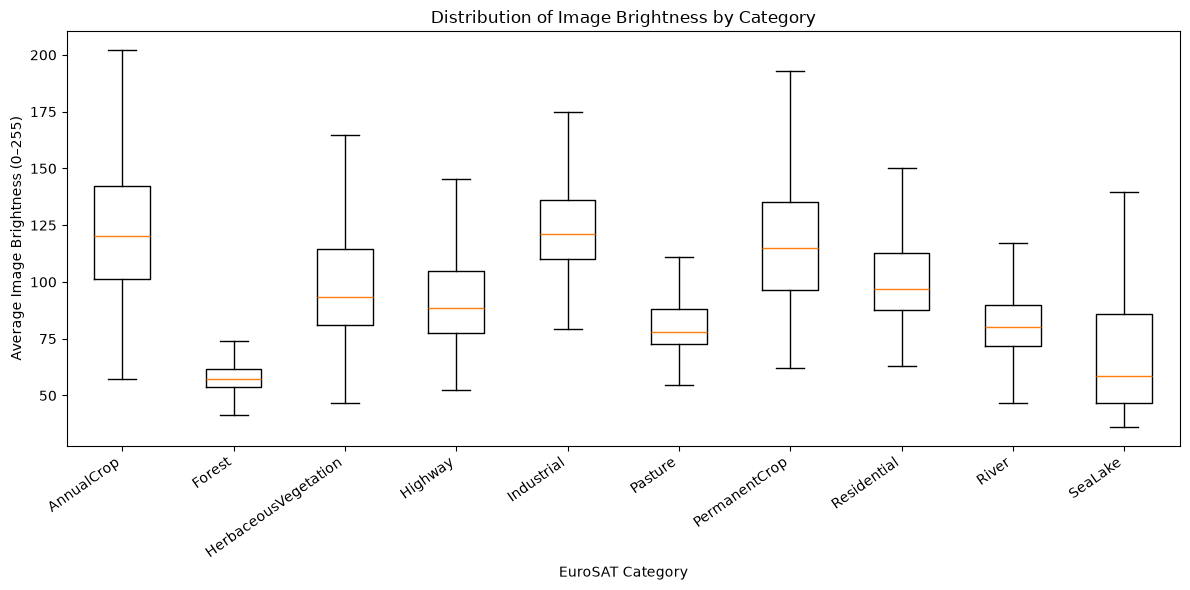

In [20]:
# Bring only the necessary columns into pandas for plotting.
brightness_data = stats_df.select(
    "category", "brightness"
).toPandas()

# Arrange the categories alphabetically.
categories = sorted(brightness_data["category"].unique())

# Prepare the brightness values for each category.
brightness_groups = [
    brightness_data.loc[
        brightness_data["category"] == category,
        "brightness"
    ].values
    for category in categories
]

plt.figure(figsize=(12, 6))

plt.boxplot(
    brightness_groups,
    tick_labels=categories,
    showfliers=False
)

plt.title("Distribution of Image Brightness by Category")
plt.xlabel("EuroSAT Category")
plt.ylabel("Average Image Brightness (0–255)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

plt.savefig(
    figures_folder / "brightness_distribution.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

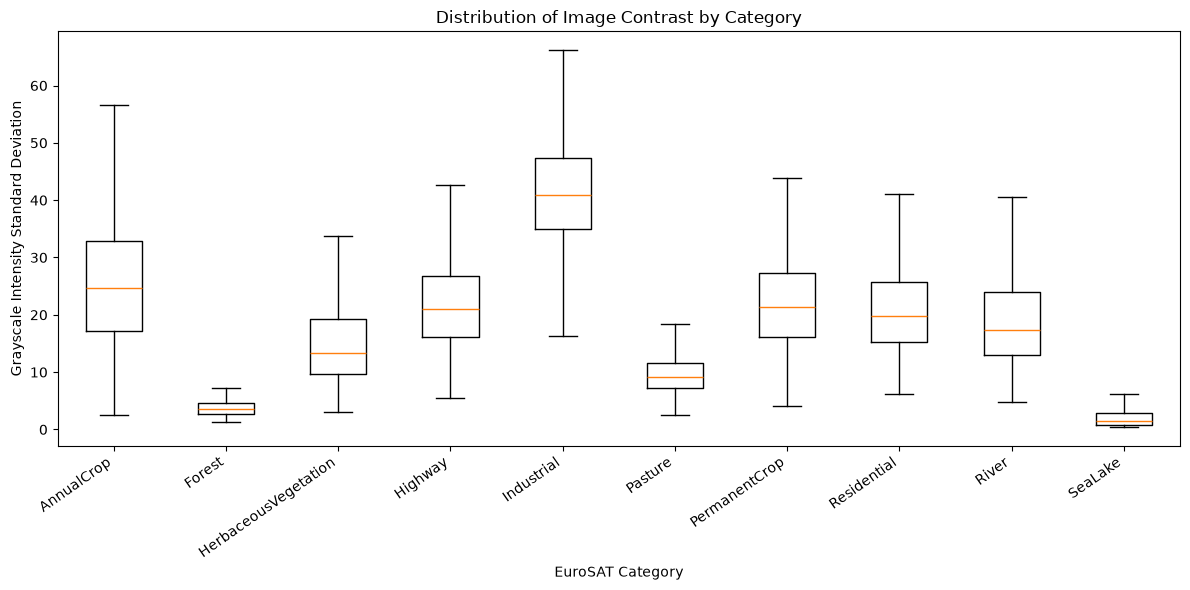

In [21]:
# Bring the contrast values into pandas.
contrast_data = stats_df.select(
    "category", "contrast"
).toPandas()

# Prepare the contrast values for each category.
contrast_groups = [
    contrast_data.loc[
        contrast_data["category"] == category,
        "contrast"
    ].values
    for category in categories
]

plt.figure(figsize=(12, 6))

plt.boxplot(
    contrast_groups,
    tick_labels=categories,
    showfliers=False
)

plt.title("Distribution of Image Contrast by Category")
plt.xlabel("EuroSAT Category")
plt.ylabel("Grayscale Intensity Standard Deviation")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

plt.savefig(
    figures_folder / "contrast_distribution.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [22]:
# Check for missing or invalid numerical values.
numeric_columns = [
    "mean_red",
    "mean_green",
    "mean_blue",
    "brightness",
    "contrast"
]

quality_checks = stats_df.select([
    F.sum(
        F.when(
            F.col(column).isNull() | F.isnan(column),
            1
        ).otherwise(0)
    ).alias(column)
    for column in numeric_columns
])

print("Missing or invalid values by feature:")
quality_checks.show()

# Confirm that the calculated image statistics are within expected ranges.
stats_df.select(
    F.min("brightness").alias("min_brightness"),
    F.max("brightness").alias("max_brightness"),
    F.min("contrast").alias("min_contrast"),
    F.max("contrast").alias("max_contrast")
).show()

Missing or invalid values by feature:
+--------+----------+---------+----------+--------+
|mean_red|mean_green|mean_blue|brightness|contrast|
+--------+----------+---------+----------+--------+
|       0|         0|        0|         0|       0|
+--------+----------+---------+----------+--------+

+-----------------+------------------+------------------+----------------+
|   min_brightness|    max_brightness|      min_contrast|    max_contrast|
+-----------------+------------------+------------------+----------------+
|36.20244598388672|216.15341186523438|0.4615163207054138|74.8967514038086|
+-----------------+------------------+------------------+----------------+



#### What the Brightness and Contrast Analysis Revealed

The boxplots show that brightness and contrast vary noticeably between categories. Forest images tend to be dark and have fairly consistent brightness, while AnnualCrop, Industrial and PermanentCrop contain a much wider range of brightness values.

Contrast reveals another interesting difference. Industrial images generally have the highest contrast, while Forest and SeaLake have very little variation between their lighter and darker areas.

However, several categories have overlapping distributions. This suggests that brightness and contrast can provide useful clues, but neither feature is reliable enough on its own to distinguish all ten classes.

The quality checks also confirmed that none of the 27,000 images has missing or invalid calculated features. Brightness ranges from 36.20 to 216.15, while contrast ranges from 0.46 to 74.90.

These findings support keeping the original RGB information and allowing the CNN to learn spatial patterns alongside colour. I'll normalise pixel values before training and consider whether modest augmentation improves generalisation.

I won't remove images simply because their brightness or contrast is unusual, as these differences may represent genuine characteristics of the land being photographed.

### 7.4 Duplicate Detection and Data Leakage

Before splitting the dataset, I want to check whether any images appear more than once.

Kaufman et al. (2012) explain that data leakage can make model performance appear more reliable than it actually is. In this project, identical images appearing in both training and testing data would be one possible source of leakage.

I'll use SHA-256 hashes to check for files with identical contents.

However, exact duplicates are not the only concern. Roberts et al. (2017) explain that spatial relationships between observations can also affect the reliability of model evaluation.

Because EuroSAT contains satellite imagery, images from nearby locations may share characteristics even when their files are different.

My duplicate check will therefore address one potential problem, while the possibility of geographic similarity remains a limitation.

In [23]:
import hashlib
import csv

# Save the hash results for later use.
hash_file = processed_folder / "eurosat_image_hashes.csv"

with open(hash_file, "w", newline="", encoding="utf-8") as file:

    writer = csv.writer(file)
    writer.writerow(["image_path", "category", "sha256"])

    for folder in class_folders:

        for image_path in sorted(folder.glob("*.jpg")):

            # Calculate a fingerprint from the original file bytes.
            file_hash = hashlib.sha256(
                image_path.read_bytes()
            ).hexdigest()

            writer.writerow([
                image_path.relative_to(project_folder).as_posix(),
                folder.name,
                file_hash
            ])

print("Image hashes calculated successfully.")
print("File:", hash_file.relative_to(project_folder))

Image hashes calculated successfully.
File: data\processed\eurosat_image_hashes.csv


In [24]:
# Load the image hashes into Spark.
hash_df = (
    spark.read
    .option("header", True)
    .csv(str(hash_file))
)

print(f"Images checked: {hash_df.count():,}")

Images checked: 27,000


In [25]:
# Find hashes that appear more than once.
duplicate_groups = (
    hash_df
    .groupBy("sha256")
    .agg(F.count("*").alias("copies"))
    .filter(F.col("copies") > 1)
)

# Count duplicate groups and additional copies.
duplicate_group_count = duplicate_groups.count()

duplicate_summary = duplicate_groups.agg(
    F.sum(F.col("copies") - 1).alias("extra_copies")
).first()

extra_copies = duplicate_summary["extra_copies"] or 0

print("Duplicate groups:", duplicate_group_count)
print("Extra duplicate files:", extra_copies)

Duplicate groups: 0
Extra duplicate files: 0


In [26]:
# Check whether matching hashes have different labels.
label_conflicts = (
    hash_df
    .groupBy("sha256")
    .agg(
        F.countDistinct("category").alias("label_count")
    )
    .filter(F.col("label_count") > 1)
)

print(
    "Exact duplicate groups with conflicting labels:",
    label_conflicts.count()
)

Exact duplicate groups with conflicting labels: 0


#### What the Duplicate Checks Revealed

The SHA-256 checks found no exact duplicates among the 27,000 images. There were also no cases where identical file contents appeared under different category labels.

This is encouraging because exact duplicates could make the final evaluation misleading if copies appeared in both the training and test sets.

However, the results do not rule out near-duplicates or satellite images taken from nearby locations. These images might share visual characteristics without having identical file contents.

Since no exact duplicates were found, I don't need to remove any images at this stage. I'll use a reproducible, stratified split and acknowledge the remaining risk of geographic similarity when interpreting the final results.

### 7.5 EDA Findings and Implications for CNN Training

The EDA helped me move beyond simply checking whether the dataset was suitable. I now have a clearer understanding of its class distribution, image characteristics and potential limitations.

The table below summarises the findings that will influence how I prepare and evaluate the CNN.

| EDA finding | Evidence | Decision for CNN development |
|---|---|---|
| Sufficient labelled data | 27,000 images across ten categories | Use supervised multiclass classification. |
| Moderate class imbalance | Categories contain 2,000–3,000 images | Use stratified splitting and evaluate performance for each class. |
| Consistent image dimensions | All images are 64 × 64 pixels | Keep the original resolution rather than resizing unnecessarily. |
| Consistent image format | All 27,000 files are JPEGs | Use a consistent RGB decoding pipeline. |
| No unreadable images detected | All files passed the initial integrity check | Retain the complete dataset, subject to further validation. |
| Different colour and lighting characteristics | Brightness and contrast vary between categories | Normalise pixel values and consider modest training-only augmentation. |
| Overlapping visual characteristics | Agricultural and vegetation categories share some visible patterns | Use convolutional layers to learn spatial features and examine confusion between categories. |
| No exact duplicates | SHA-256 found zero matching file groups | Retain all images while acknowledging the possibility of near-duplicates. |
| Possible geographic similarity | Geographic independence has not been established | Interpret random-split results cautiously and acknowledge this limitation. |

These findings give me a practical basis for the next stage. I'll prepare the images in a consistent way, preserve class proportions across the data partitions and begin with a compact CNN.

I also want to avoid making the model unnecessarily complicated before seeing how the baseline performs. I'll use the validation results to determine whether improvements such as augmentation or additional regularisation are justified.

In [27]:
# Confirm that all datasets contain the expected records.
inventory_count = image_df.count()
statistics_count = stats_df.count()
hash_count = hash_df.count()

# Confirm that all ten categories are represented.
category_count = image_df.select("category").distinct().count()

print("Final EDA verification")
print("-" * 35)

print(f"Inventory records: {inventory_count:,}")
print(f"Statistics records: {statistics_count:,}")
print(f"Hash records: {hash_count:,}")
print(f"Categories: {category_count}")
print(f"Exact duplicate groups: {duplicate_group_count}")

# Stop the notebook if an important check fails.
assert inventory_count == 27000
assert statistics_count == 27000
assert hash_count == 27000
assert category_count == 10
assert duplicate_group_count == 0

print("\nEDA verification completed successfully.")

Final EDA verification
-----------------------------------
Inventory records: 27,000
Statistics records: 27,000
Hash records: 27,000
Categories: 10
Exact duplicate groups: 0

EDA verification completed successfully.


## 8. Image Preparation and Feature Learning

The EDA showed that the images are consistent in size and format, but the categories are not perfectly balanced.

Before training the CNN, I need to divide the images into training, validation and test sets.

I'll use a stratified split to preserve the category proportions and a fixed random seed so that the same images are assigned to each set whenever the experiment is repeated.

I'll also save the split assignments. This will allow me to compare different model configurations fairly, using the same data.

### 8.1 Creating Reproducible Data Splits

I'll allocate 70% of the images to training, 15% to validation and 15% to testing.

The training set will be used to teach the CNN, the validation set will help me assess and improve it, and the test set will be reserved for the final evaluation.

In [28]:
from sklearn.model_selection import train_test_split

# Use the image inventory generated during EDA.
image_data = pd.read_csv(
    processed_folder / "eurosat_inventory.csv"
)

# Keep only the fields needed for training.
image_data = image_data[["image_path", "category"]]

# First split: 70% training, 30% remaining.
train_data, remaining_data = train_test_split(
    image_data,
    test_size=0.30,
    stratify=image_data["category"],
    random_state=42
)

# Second split: divide the remaining 30% equally.
val_data, test_data = train_test_split(
    remaining_data,
    test_size=0.50,
    stratify=remaining_data["category"],
    random_state=42
)

# Add a column identifying each partition.
train_data = train_data.assign(split="train")
val_data = val_data.assign(split="validation")
test_data = test_data.assign(split="test")

print(f"Training images: {len(train_data):,}")
print(f"Validation images: {len(val_data):,}")
print(f"Test images: {len(test_data):,}")

Training images: 18,900
Validation images: 4,050
Test images: 4,050


In [29]:
# Combine the three partitions into one reproducible record.
split_data = pd.concat(
    [train_data, val_data, test_data],
    ignore_index=True
)

# Save the assignments using relative image paths.
split_file = processed_folder / "eurosat_splits.csv"

split_data.to_csv(split_file, index=False)

print("Data splits saved successfully.")
print("File:", split_file.relative_to(project_folder))

Data splits saved successfully.
File: data\processed\eurosat_splits.csv


In [30]:
# Check the number of images in each partition.
split_counts = split_data["split"].value_counts()

display(split_counts)

# Check that all categories appear in every partition.
class_split_counts = pd.crosstab(
    split_data["category"],
    split_data["split"]
)

display(class_split_counts)

# Verify that every image appears exactly once.
assert len(split_data) == 27000
assert split_data["image_path"].is_unique

# Confirm that the expected partitions exist.
assert set(split_data["split"]) == {
    "train", "validation", "test"
}

# Confirm that every category is represented in every split.
assert (class_split_counts > 0).all().all()

print("All split checks passed.")

split
train         18900
validation     4050
test           4050
Name: count, dtype: int64

split,test,train,validation
category,,,
AnnualCrop,450,2100,450
Forest,450,2100,450
HerbaceousVegetation,450,2100,450
Highway,375,1750,375
Industrial,375,1750,375
Pasture,300,1400,300
PermanentCrop,375,1750,375
Residential,450,2100,450
River,375,1750,375


All split checks passed.


#### 8.1.1 Results and Interpretation

The stratified split produced **18,900 training images (70%)**, **4,050 validation images (15%)** and **4,050 test images (15%)**, exactly as planned.

Looking at the category counts, I can see that the original class proportions have been preserved. For example, AnnualCrop has 2,100 training images and 450 images in each of the validation and test sets. Pasture, the smallest category, has 1,400 training images and 300 in each remaining set.

All 27,000 images were assigned successfully, with no repeated file paths, and every category is represented in all three partitions. The split assignments are also saved in `data/processed/eurosat_splits.csv`, making them available for future experiments.

These results give me a consistent starting point for training and comparing CNN models. I will use the validation set to monitor training and select improvements, while keeping the test set untouched until the final evaluation.

One limitation remains: although the partitions do not share image files, the dataset does not provide sufficient location information to establish geographic independence. The final results will therefore describe performance on held-out EuroSAT images rather than entirely new geographic regions.

### 8.2 Preparing the TensorFlow Image Pipeline

The dataset is now divided into three reproducible partitions, but TensorFlow still needs the image files converted into numerical inputs.

I'll load the original JPEG images using the relative paths saved in the split file. Since the EDA confirmed that every image is 64 × 64 pixels, there is no need to resize them.

I'll also scale the pixel values from 0–255 to 0–1 and convert the category names into numerical labels.

Finally, I'll organise the images into batches and use prefetching to keep the data-loading process efficient during training.

In [31]:
# Create a consistent numerical label for each category.
class_names = sorted(split_data["category"].unique())

class_to_index = {
    name: index
    for index, name in enumerate(class_names)
}

# Add numerical labels to the saved split information.
split_data["label"] = split_data["category"].map(class_to_index)

print("Class labels:\n")

for name, index in class_to_index.items():
    print(f"{index}: {name}")

print(f"\nNumber of classes: {len(class_names)}")

Class labels:

0: AnnualCrop
1: Forest
2: HerbaceousVegetation
3: Highway
4: Industrial
5: Pasture
6: PermanentCrop
7: Residential
8: River
9: SeaLake

Number of classes: 10


In [32]:
import json

# Save the class-to-index mapping.
label_file = processed_folder / "class_mapping.json"

with open(label_file, "w", encoding="utf-8") as file:
    json.dump(class_to_index, file, indent=4)

# Update the split CSV with numerical labels.
split_data.to_csv(split_file, index=False)

print("Class mapping saved successfully.")
print("Split assignments updated with numerical labels.")

Class mapping saved successfully.
Split assignments updated with numerical labels.


In [33]:
# Check that all image paths still point to valid files.
missing_files = [
    path
    for path in split_data["image_path"]
    if not (project_folder / path).is_file()
]

print("Missing image files:", len(missing_files))

assert len(missing_files) == 0, "Some image files could not be found."

print("All image paths verified successfully.")

Missing image files: 0
All image paths verified successfully.


#### Loading and Normalising the Images

My earlier checks confirmed that the files are JPEG images with consistent dimensions, so I can use the same loading process for every image.

I'll decode each image into three RGB channels and scale the pixel values to a range of 0–1.

This keeps the input format consistent and makes the numerical values more suitable for neural network training. I'll also check the resulting shapes and values before starting the CNN.

In [34]:
# Load and prepare one image at a time.
def load_image(image_path, label):

    # Read the JPEG file.
    image_bytes = tf.io.read_file(image_path)

    # Decode it into a three-channel RGB image.
    image = tf.io.decode_jpeg(image_bytes, channels=3)

    # Convert pixel values from 0–255 to 0–1.
    image = tf.image.convert_image_dtype(image, tf.float32)

    # Confirm the expected shape for the CNN.
    image = tf.ensure_shape(image, (64, 64, 3))

    return image, label

In [35]:
# Set reproducible training parameters.
SEED = 42
BATCH_SIZE = 32

tf.keras.utils.set_random_seed(SEED)

def create_dataset(data, training=False):

    # Convert relative image paths into paths for the current computer.
    image_paths = [
        str(project_folder / path)
        for path in data["image_path"]
    ]

    labels = data["label"].to_numpy(dtype=np.int32)

    # Create a TensorFlow dataset from the paths and labels.
    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    # Shuffle only the training data.
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(data),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    # Decode and normalise images.
    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    # Group images into batches.
    dataset = dataset.batch(BATCH_SIZE)

    # Prepare the next batch while the model processes the current one.
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


# Build the three datasets using the saved split assignments.
train_dataset = create_dataset(
    split_data[split_data["split"] == "train"],
    training=True
)

val_dataset = create_dataset(
    split_data[split_data["split"] == "validation"]
)

test_dataset = create_dataset(
    split_data[split_data["split"] == "test"]
)

print("TensorFlow datasets created successfully.")

TensorFlow datasets created successfully.


In [36]:
# Examine the first batch of training images.
for images, labels in train_dataset.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)

    print("Minimum pixel value:", float(tf.reduce_min(images)))
    print("Maximum pixel value:", float(tf.reduce_max(images)))

    print("Data type:", images.dtype)

    print("Example labels:", labels[:10].numpy())

Image batch shape: (32, 64, 64, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0784313753247261
Maximum pixel value: 1.0
Data type: <dtype: 'float32'>
Example labels: [9 9 8 2 8 6 0 6 6 2]


#### 8.2.1 Results and Interpretation

The TensorFlow pipeline successfully produced a batch of 32 RGB images, each with the expected shape of 64 × 64 × 3. The labels also have the correct shape, with one numerical category assigned to each image.

The pixel values in the inspected batch ranged from 0.0784 to 1.0, and the images were stored as `float32` values. This confirms that the sample batch is consistent with the intended normalisation process.

The pipeline now loads and prepares images in batches, rather than holding the entire decoded dataset in memory. It also uses prefetching to help keep training efficient.

These results show that the image-loading process is working as intended for the inspected batch. I can now move on to designing the CNN, using the original image dimensions and the ten numerical class labels established during preparation.

## 9. CNN Development and Training

The image preparation checks confirm that TensorFlow can load the RGB images in the expected shape and numerical format.

I'll begin with a relatively small CNN to establish a baseline before testing possible improvements.

The network will use convolutional layers to learn visual patterns, pooling layers to reduce the feature-map dimensions and a final classification layer to predict one of the ten EuroSAT categories.

I want the model to be capable enough to learn meaningful features without introducing unnecessary complexity. I'll examine its training and validation results before deciding whether the architecture needs improvement.

### 9.1 Designing the Baseline CNN

I'll begin with a compact CNN designed to classify the 64 × 64 RGB images into ten categories.

According to LeCun, Bengio and Hinton (2015), deep learning models can develop increasingly complex representations through successive processing layers. CNNs are particularly useful for images because their convolutional layers learn spatial features such as edges, textures and patterns.

My baseline will use three convolutional layers, each followed by max-pooling. I'll then use global average pooling and a small dense layer before the final ten-class output.

I've deliberately kept the architecture relatively small so that I can establish a baseline without introducing unnecessary computational demands.

In [37]:
from tensorflow.keras import layers, models

# Set the random seed for reproducibility.
tf.keras.utils.set_random_seed(42)

# Build a compact CNN for 64 × 64 RGB images.
baseline_model = models.Sequential([
    layers.Input(shape=(64, 64, 3)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(64, activation="relu"),

    layers.Dense(10, activation="softmax")
])

# Display the model architecture and parameter counts.
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape          ┃      Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)               │ (None, 64, 64, 32)    │          896 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ max_pooling2d (MaxPooling2D)  │ (None, 32, 32, 32)    │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ conv2d_1 (Conv2D)             │ (None, 32, 32, 64)    │       18,496 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ max_pooling2d_1               │ (None, 16, 16, 64)    │            0 │
│ (MaxPooling2D)                │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ conv2d_2 (Conv2D)             │ (None, 16, 16, 128)   │       73,856 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ max_pooling2d_2               │ (None, 8, 8, 128)     │            0 │
│ (MaxPooling2D)                │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ global_average_pooling2d      │ (None, 128)           │            0 │
│ (GlobalAveragePooling2D)      │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense (Dense)                 │ (None, 64)            │        8,256 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense_1 (Dense)               │ (None, 10)            │          650 │
└───────────────────────────────┴───────────────────────┴──────────────┘

 Total params: 102,154 (399.04 KB)

 Trainable params: 102,154 (399.04 KB)

 Non-trainable params: 0 (0.00 B)

In [38]:
# Configure how the CNN will learn.
baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Baseline CNN compiled successfully.")

Baseline CNN compiled successfully.


#### 9.1.1 Architecture and Parameter Summary

The baseline CNN was created successfully with **102,154 trainable parameters** and no frozen layers.

The three convolutional layers increase the number of feature maps from 32 to 64 and then 128, while the pooling layers gradually reduce their spatial dimensions from 64 × 64 to 8 × 8.

I chose global average pooling instead of flattening the final feature maps because it keeps the number of parameters relatively low. The model then uses a small dense layer before producing probabilities for the ten EuroSAT categories.

This gives me a manageable starting point for training. I haven't included dropout or data augmentation yet because I first want to see how the baseline model performs.

TensorFlow also confirmed that GPU acceleration is unavailable in my current Windows environment. I'll therefore train the model using the CPU and keep the initial experiment relatively small.

### 9.2 Training the Baseline CNN

I'll now train the baseline CNN using the 18,900 training images and monitor its performance on the 4,050 validation images.

I'll start with a maximum of 15 epochs and a batch size of 32. These settings should give the model enough opportunities to learn while keeping the initial experiment manageable.

To reduce unnecessary training, I'll use early stopping based on validation loss. I'll also save the best-performing model so that later evaluations use the weights from the most successful training epoch.

I won't use the test set at this stage. It will remain reserved for evaluating the selected model after development.

In [39]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Save the baseline model inside the project.
baseline_model_path = models_folder / "baseline_cnn.keras"

# Stop training if validation loss stops improving.
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Save the model whenever validation loss improves.
model_checkpoint = ModelCheckpoint(
    filepath=str(baseline_model_path),
    monitor="val_loss",
    save_best_only=True
)

callbacks = [
    early_stopping,
    model_checkpoint
]

print("Training callbacks configured successfully.")

Training callbacks configured successfully.


In [40]:
# Train the baseline CNN.
baseline_history = baseline_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=15,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/15


C:\Users\tvmos\anaconda3\envs\pdan8412_cnn\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


591/591 ━━━━━━━━━━━━━━━━━━━━ 21s 32ms/step - accuracy: 0.4379 - loss: 1.4531 - val_accuracy: 0.5511 - val_loss: 1.2078
Epoch 2/15
591/591 ━━━━━━━━━━━━━━━━━━━━ 19s 32ms/step - accuracy: 0.5903 - loss: 1.0928 - val_accuracy: 0.6486 - val_loss: 0.9185
Epoch 3/15
591/591 ━━━━━━━━━━━━━━━━━━━━ 19s 33ms/step - accuracy: 0.6677 - loss: 0.8990 - val_accuracy: 0.7123 - val_loss: 0.7713
Epoch 4/15
591/591 ━━━━━━━━━━━━━━━━━━━━ 21s 35ms/step - accuracy: 0.7101 - loss: 0.7839 - val_accuracy: 0.7121 - val_loss: 0.7895
Epoch 5/15
591/591 ━━━━━━━━━━━━━━━━━━━━ 21s 35ms/step - accuracy: 0.7396 - loss: 0.7051 - val_accuracy: 0.7642 - val_loss: 0.6395
Epoch 6/15
591/591 ━━━━━━━━━━━━━━━━━━━━ 21s 35ms/step - accuracy: 0.7559 - loss: 0.6687 - val_accuracy: 0.7563 - val_loss: 0.6762
Epoch 7/15
591/591 ━━━━━━━━━━━━━━━━━━━━ 21s 36ms/step - accuracy: 0.7664 - loss: 0.6359 - val_accuracy: 0.7264 - val_loss: 0.7409
Epoch 8/15
591/591 ━━━━━━━━━━━━━━━━━━━━ 21s 36ms/step - accuracy: 0.7765 - loss: 0.6153 - val_accurac

#### 9.2.1 Baseline Training Results

The baseline CNN completed eight epochs before early stopping was triggered. Training accuracy improved from 43.79% in the first epoch to 77.65% in the eighth, showing that the model was learning useful patterns from the images.

However, the best validation results occurred at **epoch 5**, with an accuracy of **76.42%** and a loss of **0.6395**.

After this point, training accuracy continued improving, but validation loss increased. This suggests that the model was beginning to fit the training data more closely without achieving better results on unseen validation images.

Early stopping prevented unnecessary training, while the checkpoint saved the weights from the epoch with the lowest validation loss.

These results give me a useful baseline, but they also suggest that the model could benefit from better generalisation. Before making changes, I'll examine the training curves to understand the learning behaviour more clearly.

### 9.3 Analysing Training Performance

The training results suggest that the CNN learned steadily during its first few epochs, but validation performance stopped improving after epoch 5.

I'll compare the training and validation accuracy and loss curves to investigate this behaviour.

These graphs should help me understand whether the model is beginning to overfit and provide evidence for deciding what to improve next.

In [41]:
# Convert the training results into a table.
baseline_results = pd.DataFrame(baseline_history.history)

# Add the epoch numbers.
baseline_results.insert(
    0,
    "epoch",
    range(1, len(baseline_results) + 1)
)

# Save the results for reproducibility.
history_file = processed_folder / "baseline_training_history.csv"

baseline_results.to_csv(history_file, index=False)

display(baseline_results)

# Identify the epoch with the lowest validation loss.
best_epoch = baseline_results.loc[
    baseline_results["val_loss"].idxmin()
]

print(f"Epochs completed: {len(baseline_results)}")
print(f"Best epoch: {int(best_epoch['epoch'])}")
print(f"Best validation accuracy: {best_epoch['val_accuracy']:.2%}")
print(f"Lowest validation loss: {best_epoch['val_loss']:.4f}")

,epoch,accuracy,loss,val_accuracy,val_loss
0,1,0.437937,1.453109,0.551111,1.207779
1,2,0.590265,1.092802,0.648642,0.918550
2,3,0.667725,0.898964,0.712346,0.771272
3,4,0.710106,0.783920,0.712099,0.789509
4,5,0.739577,0.705106,0.764198,0.639547
5,6,0.755873,0.668714,0.756296,0.676172
6,7,0.766402,0.635919,0.726420,0.740856
7,8,0.776455,0.615284,0.741975,0.673907


Epochs completed: 8
Best epoch: 5
Best validation accuracy: 76.42%
Lowest validation loss: 0.6395


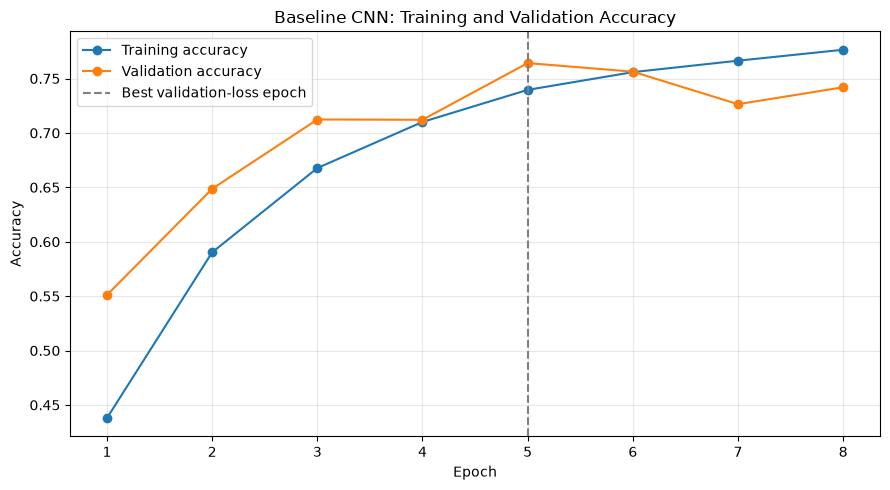

In [42]:
plt.figure(figsize=(9, 5))

plt.plot(
    baseline_results["epoch"],
    baseline_results["accuracy"],
    marker="o",
    label="Training accuracy"
)

plt.plot(
    baseline_results["epoch"],
    baseline_results["val_accuracy"],
    marker="o",
    label="Validation accuracy"
)

plt.axvline(
    int(best_epoch["epoch"]),
    linestyle="--",
    color="gray",
    label="Best validation-loss epoch"
)

plt.title("Baseline CNN: Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(baseline_results["epoch"])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures_folder / "baseline_accuracy.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

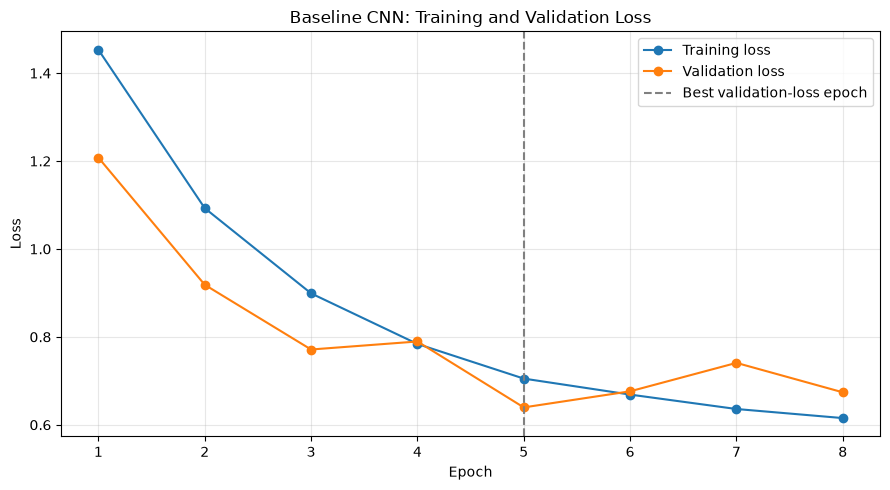

In [43]:
plt.figure(figsize=(9, 5))

plt.plot(
    baseline_results["epoch"],
    baseline_results["loss"],
    marker="o",
    label="Training loss"
)

plt.plot(
    baseline_results["epoch"],
    baseline_results["val_loss"],
    marker="o",
    label="Validation loss"
)

plt.axvline(
    int(best_epoch["epoch"]),
    linestyle="--",
    color="gray",
    label="Best validation-loss epoch"
)

plt.title("Baseline CNN: Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(baseline_results["epoch"])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures_folder / "baseline_loss.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

#### 9.3.1 What the Training Curves Revealed

The training curves show that the baseline CNN learned steadily during its first few epochs. Training accuracy increased from 43.79% to 77.65%, while training loss continued to decrease.

However, validation performance followed a different pattern. The best results occurred at epoch 5, where validation accuracy reached **76.42%** and validation loss dropped to **0.6395**.

After epoch 5, training accuracy continued improving, but validation loss increased. This suggests that the model was beginning to fit the training images more closely without improving its ability to classify unseen validation images.

Early stopping ended training after eight epochs and restored the weights from the best validation-loss epoch.

I now have a useful baseline for comparison. Rather than immediately increasing the model's size, I'll first investigate whether modest image augmentation can help it learn features that generalise better.

### 9.4 Improving the CNN Through Data Augmentation

The baseline CNN achieved its best validation results at epoch 5. After that, training accuracy continued increasing while validation loss became worse, suggesting that the model was beginning to overfit.

Shorten and Khoshgoftaar (2019) explain that image augmentation can introduce useful variation into training data and help improve generalisation.

I'll investigate whether this approach improves my CNN by introducing random horizontal and vertical flips, along with modest rotations.

Because the images are captured from above, their orientation is not necessarily important for identifying the land-cover category.

I'll keep the original CNN architecture and main training settings unchanged. This will allow me to compare the augmented model with the baseline using the same validation images.

In [44]:
from tensorflow.keras import layers, models

# Reset the seed for a reproducible experiment.
tf.keras.utils.set_random_seed(42)

# Apply transformations only during training.
augmentation = models.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.10)
], name="image_augmentation")

# Build the same CNN architecture with augmentation added.
augmented_model = models.Sequential([
    layers.Input(shape=(64, 64, 3)),

    augmentation,

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(64, activation="relu"),

    layers.Dense(10, activation="softmax")
])

augmented_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape          ┃      Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ image_augmentation            │ (None, 64, 64, 3)     │            0 │
│ (Sequential)                  │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ conv2d_3 (Conv2D)             │ (None, 64, 64, 32)    │          896 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ max_pooling2d_3               │ (None, 32, 32, 32)    │            0 │
│ (MaxPooling2D)                │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ conv2d_4 (Conv2D)             │ (None, 32, 32, 64)    │       18,496 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ max_pooling2d_4               │ (None, 16, 16, 64)    │            0 │
│ (MaxPooling2D)                │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ conv2d_5 (Conv2D)             │ (None, 16, 16, 128)   │       73,856 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ max_pooling2d_5               │ (None, 8, 8, 128)     │            0 │
│ (MaxPooling2D)                │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ global_average_pooling2d_1    │ (None, 128)           │            0 │
│ (GlobalAveragePooling2D)      │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense_2 (Dense)               │ (None, 64)            │        8,256 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense_3 (Dense)               │ (None, 10)            │          650 │
└───────────────────────────────┴───────────────────────┴──────────────┘

 Total params: 102,154 (399.04 KB)

 Trainable params: 102,154 (399.04 KB)

 Non-trainable params: 0 (0.00 B)

In [45]:
# Use the same optimiser, learning rate and loss as the baseline.
augmented_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Augmented CNN compiled successfully.")

Augmented CNN compiled successfully.


In [46]:
# Save the improved model separately from the baseline.
augmented_model_path = models_folder / "augmented_cnn.keras"

augmented_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(augmented_model_path),
        monitor="val_loss",
        save_best_only=True
    )
]

print("Augmented model callbacks configured.")

Augmented model callbacks configured.


#### 9.4.1 Verifying the Augmented Architecture

The augmented CNN was created successfully with **102,154 trainable parameters**, exactly the same as the baseline.

The model summary confirms that the new augmentation layers preserve the original 64 × 64 × 3 input shape and do not introduce additional trainable parameters.

This means I can investigate the effect of augmentation without changing the underlying CNN architecture.

The optimiser, learning rate, loss function and early-stopping settings also remain unchanged. I'll use the same training and validation partitions, allowing me to compare the two experiments under similar conditions.

### 9.4.2 Training the Augmented CNN

I'll now train the augmented CNN using the same 18,900 training images and 4,050 validation images as the baseline.

The model will receive randomly flipped and rotated versions of training images, while validation images will remain unchanged.

I'll again allow a maximum of 15 epochs and use early stopping based on validation loss.

My aim is to determine whether augmentation helps the model generalise better, rather than simply improving its ability to recognise the training images.

In [47]:
# Train the augmented CNN using the same dataset and settings.
augmented_history = augmented_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=15,
    callbacks=augmented_callbacks,
    shuffle=False,
    verbose=1
)

Epoch 1/15
591/591 ━━━━━━━━━━━━━━━━━━━━ 23s 37ms/step - accuracy: 0.4253 - loss: 1.5126 - val_accuracy: 0.4872 - val_loss: 1.3781
Epoch 2/15
591/591 ━━━━━━━━━━━━━━━━━━━━ 22s 36ms/step - accuracy: 0.5974 - loss: 1.0905 - val_accuracy: 0.6126 - val_loss: 1.0592
Epoch 3/15
591/591 ━━━━━━━━━━━━━━━━━━━━ 21s 36ms/step - accuracy: 0.6816 - loss: 0.8703 - val_accuracy: 0.6998 - val_loss: 0.8682
Epoch 4/15
591/591 ━━━━━━━━━━━━━━━━━━━━ 23s 39ms/step - accuracy: 0.7203 - loss: 0.7670 - val_accuracy: 0.7027 - val_loss: 0.9048
Epoch 5/15
591/591 ━━━━━━━━━━━━━━━━━━━━ 25s 42ms/step - accuracy: 0.7467 - loss: 0.7009 - val_accuracy: 0.7059 - val_loss: 0.7811
Epoch 6/15
591/591 ━━━━━━━━━━━━━━━━━━━━ 24s 40ms/step - accuracy: 0.7575 - loss: 0.6643 - val_accuracy: 0.7412 - val_loss: 0.7448
Epoch 7/15
591/591 ━━━━━━━━━━━━━━━━━━━━ 24s 41ms/step - accuracy: 0.7759 - loss: 0.6227 - val_accuracy: 0.7430 - val_loss: 0.7393
Epoch 8/15
591/591 ━━━━━━━━━━━━━━━━━━━━ 24s 41ms/step - accuracy: 0.7735 - loss: 0.6198 - 

In [48]:
# Convert the augmented training history to a DataFrame.
augmented_results = pd.DataFrame(augmented_history.history)

# Add epoch numbers.
augmented_results.insert(
    0,
    "epoch",
    range(1, len(augmented_results) + 1)
)

# Save the history for later comparison.
augmented_history_file = (
    processed_folder / "augmented_training_history.csv"
)

augmented_results.to_csv(
    augmented_history_file,
    index=False
)

display(augmented_results)

# Find the epoch with the lowest validation loss.
augmented_best = augmented_results.loc[
    augmented_results["val_loss"].idxmin()
]

print(f"Epochs completed: {len(augmented_results)}")
print(f"Best epoch: {int(augmented_best['epoch'])}")
print(f"Best validation accuracy at selected epoch: {augmented_best['val_accuracy']:.2%}")
print(f"Lowest validation loss: {augmented_best['val_loss']:.4f}")

print("Training history saved successfully.")

,epoch,accuracy,loss,val_accuracy,val_loss
0,1,0.425291,1.512647,0.487161,1.378136
1,2,0.597354,1.090485,0.612593,1.059171
2,3,0.681640,0.870317,0.699753,0.868181
3,4,0.720265,0.767035,0.702716,0.904770
4,5,0.746720,0.700948,0.705926,0.781121
5,6,0.757460,0.664287,0.741235,0.744796
6,7,0.775926,0.622715,0.742963,0.739252
7,8,0.773545,0.619825,0.743951,0.736788
8,9,0.794233,0.581953,0.792593,0.571371
9,10,0.797037,0.562714,0.733333,0.787466


Epochs completed: 12
Best epoch: 9
Best validation accuracy at selected epoch: 79.26%
Lowest validation loss: 0.5714
Training history saved successfully.


In [49]:
# Compare both models at their best validation-loss epochs.
comparison = pd.DataFrame({
    "Model": ["Baseline CNN", "Augmented CNN"],
    "Best epoch": [
        int(best_epoch["epoch"]),
        int(augmented_best["epoch"])
    ],
    "Validation accuracy": [
        best_epoch["val_accuracy"],
        augmented_best["val_accuracy"]
    ],
    "Validation loss": [
        best_epoch["val_loss"],
        augmented_best["val_loss"]
    ],
    "Epochs completed": [
        len(baseline_results),
        len(augmented_results)
    ]
})

display(
    comparison.style.format({
        "Validation accuracy": "{:.2%}",
        "Validation loss": "{:.4f}"
    })
)

# Calculate how augmentation changed validation accuracy.
accuracy_change = (
    augmented_best["val_accuracy"]
    - best_epoch["val_accuracy"]
) * 100

print(
    f"Change in validation accuracy: "
    f"{accuracy_change:+.2f} percentage points"
)

,Model,Best epoch,Validation accuracy,Validation loss,Epochs completed
0,Baseline CNN,5,76.42%,0.6395,8
1,Augmented CNN,9,79.26%,0.5714,12


Change in validation accuracy: +2.84 percentage points


#### 9.4.3 Comparing the Baseline and Augmented CNNs

The augmented CNN achieved better validation results than the baseline. Its accuracy increased from **76.42% to 79.26%**, an improvement of **2.84 percentage points**, while validation loss decreased from **0.6395 to 0.5714**.

The augmented model reached its lowest validation loss at epoch 9 and completed 12 epochs before early stopping, compared with eight epochs for the baseline.

This is encouraging because both models used the same architecture, training images, validation images and main training settings. The principal difference was the addition of random flips and rotations during training.

The results suggest that augmentation helped the CNN learn features that generalised better to the validation images. This is consistent with the variation in image patterns I observed during EDA.

However, each model was trained only once, so I cannot rule out the influence of random variation. The improvement is promising within this experiment, but it does not establish that augmentation will always perform better.

Based on the lower validation loss and higher validation accuracy, I'll select the augmented CNN for final evaluation using the held-out test set.

### 9.5 Selecting the Final CNN

The comparison showed that the augmented CNN achieved the lowest validation loss and highest validation accuracy of the two experiments.

I'll therefore select the augmented model for final evaluation.

To make sure the results are reproducible, I'll load the saved checkpoint rather than relying on the model currently in memory. This also confirms that the model can be restored for future use.

The test dataset has not been used to train or select either model, so it remains available for an independent final evaluation.

In [51]:
# Load the best augmented CNN from its saved checkpoint.
final_model = tf.keras.models.load_model(
    str(augmented_model_path)
)

print("Selected CNN loaded successfully.")
print("Model:", augmented_model_path.relative_to(project_folder))
print("Output shape:", final_model.output_shape)
print("Trainable parameters:", final_model.count_params())

Selected CNN loaded successfully.
Model: models\augmented_cnn.keras
Output shape: (None, 10)
Trainable parameters: 102154


## 10. Model Evaluation and Interpretation

The augmented CNN achieved the strongest validation results, so I'll now evaluate its performance on the 4,050 images reserved for testing.

These images were not used during training or model selection. This gives me a more reliable indication of how the selected CNN performs on previously unseen examples from the EuroSAT dataset.

I'll begin by measuring overall accuracy and loss. However, because the dataset contains ten categories with slightly different class sizes, I also need to investigate precision, recall and F1-score for individual categories.

I'll then use a confusion matrix and examples of incorrect predictions to understand where the model performs well and where it still struggles.

### 10.1 Overall Test Performance

In [52]:
# Evaluate the selected model on the held-out test dataset.
test_loss, test_accuracy = final_model.evaluate(
    test_dataset,
    verbose=1
)

print(f"\nTest accuracy: {test_accuracy:.2%}")
print(f"Test loss: {test_loss:.4f}")

127/127 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.8077 - loss: 0.5449

Test accuracy: 80.77%
Test loss: 0.5449


#### 10.1.1 Overall Test Results

The selected augmented CNN achieved **80.77% accuracy** and a loss of **0.5449** on the 4,050 held-out test images.

This means the model correctly classified approximately eight out of every ten images it had not encountered during training.

The test accuracy is also close to the **79.26% validation accuracy** recorded at the selected epoch, which is encouraging. It suggests that the model's performance on the test set is reasonably consistent with what I observed during development.

However, the overall result does not show whether the model performs equally well across all ten categories. Some land-cover types may be much easier to recognise than others.

I'll therefore examine precision, recall, F1-score and the confusion matrix to understand the remaining classification errors in more detail.

### 10.2 Precision, Recall and F1-Score

The selected CNN achieved 80.77% test accuracy, but this does not tell me how reliably it recognises each of the ten categories.

Sokolova and Lapalme (2009) explain that different classification measures capture different aspects of model performance. This makes it important to look beyond overall accuracy.

I'll calculate precision, recall and F1-score for each category, along with macro and weighted averages.

This is particularly relevant because my EDA showed that the categories contain different numbers of images and share some visual characteristics.

I want to identify which land-cover types the model recognises reliably and which ones account for more of its classification errors.

In [53]:
# Generate predicted probabilities for the test images.
test_probabilities = final_model.predict(
    test_dataset,
    verbose=1
)

# Select the category with the highest predicted probability.
y_pred = np.argmax(test_probabilities, axis=1)

# Collect the true labels in the same order.
y_true = np.concatenate([
    labels.numpy()
    for _, labels in test_dataset
])

print("Test predictions:", len(y_pred))
print("True labels:", len(y_true))

# Confirm that every test image has a prediction.
assert len(y_pred) == len(y_true) == 4050

print("Prediction and label counts match.")

127/127 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step
Test predictions: 4050
True labels: 4050
Prediction and label counts match.


In [54]:
from sklearn.metrics import classification_report

# Calculate precision, recall and F1-score for each category.
report = classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    digits=4,
    zero_division=0
)

print(report)

                      precision    recall  f1-score   support

          AnnualCrop     0.9023    0.8000    0.8481       450
              Forest     0.9214    0.9378    0.9295       450
HerbaceousVegetation     0.6592    0.8467    0.7412       450
             Highway     0.7219    0.3253    0.4485       375
          Industrial     0.8225    0.9760    0.8927       375
             Pasture     0.8425    0.8200    0.8311       300
       PermanentCrop     0.6082    0.6747    0.6397       375
         Residential     0.9509    0.9044    0.9271       450
               River     0.6862    0.8107    0.7433       375
             SeaLake     0.9716    0.9111    0.9404       450

            accuracy                         0.8077      4050
           macro avg     0.8087    0.8007    0.7942      4050
        weighted avg     0.8147    0.8077    0.8012      4050



In [55]:
# Create a structured classification report.
report_data = classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_data).transpose()

# Save the evaluation metrics.
report_file = processed_folder / "cnn_classification_report.csv"

report_df.to_csv(report_file)

print("Classification report saved successfully.")
print("File:", report_file.relative_to(project_folder))

Classification report saved successfully.
File: data\processed\cnn_classification_report.csv


#### 10.2.1 What the Classification Report Revealed

The classification report shows that the CNN's performance is not equally strong across all ten categories.

SeaLake, Forest and Residential achieved the highest F1-scores, at **94.04%, 92.95% and 92.71%** respectively. These results suggest that the model learned relatively reliable features for recognising these categories.

Highway was the weakest category, with a recall of only **32.53%** and an F1-score of **44.85%**. This means the model failed to recognise most of the Highway images in the test set. PermanentCrop also performed relatively poorly, with an F1-score of **63.97%**.

An interesting finding is that Pasture, the smallest category, achieved an F1-score of **83.11%**. This suggests that class size alone does not explain the differences in performance.

The overall accuracy was **80.77%**, but the macro-average F1-score was lower at **79.42%**. This highlights why accuracy alone would give an incomplete picture of the model's performance.

These results raise an important question: which categories are being mistaken for Highway and PermanentCrop? I'll investigate this using a confusion matrix and compare the findings with the visual similarities identified during EDA.

### 10.3 Confusion Matrix and Classification Errors

The classification report revealed substantial differences between categories, particularly the low recall for Highway and the weaker F1-score for PermanentCrop.

I'll now use a confusion matrix to investigate where these errors occur.

The matrix will show how often images from one category were assigned to another. This should help me identify which land-cover types the CNN struggles to distinguish.

I'll also compare the results with the similarities I noticed during EDA to see whether the model's mistakes follow any recognisable patterns.

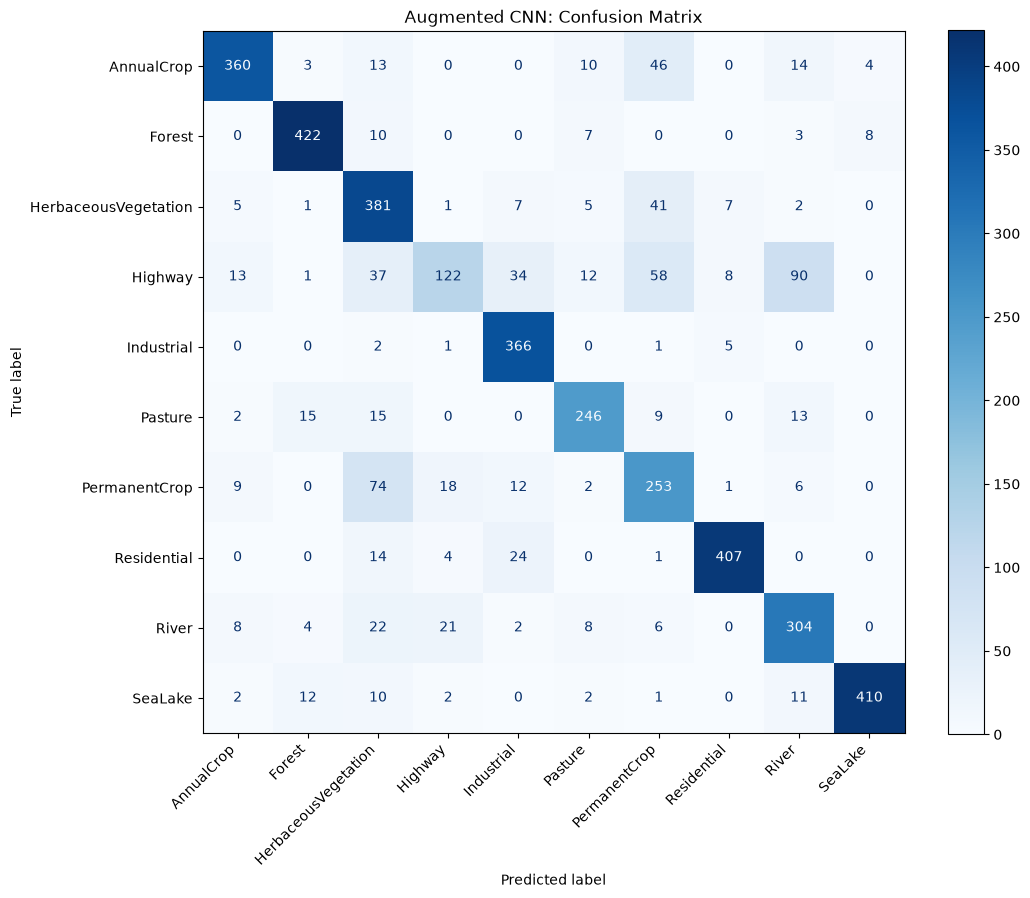

In [56]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate the confusion matrix.
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(class_names))
)

# Display the confusion matrix.
fig, ax = plt.subplots(figsize=(11, 9))

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display_cm.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=True
)

plt.title("Augmented CNN: Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    figures_folder / "cnn_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [57]:
# Collect all incorrect classification pairs.
classification_errors = []

for actual_index, actual_name in enumerate(class_names):

    for predicted_index, predicted_name in enumerate(class_names):

        if actual_index != predicted_index:

            error_count = cm[actual_index, predicted_index]

            classification_errors.append({
                "Actual category": actual_name,
                "Predicted category": predicted_name,
                "Errors": int(error_count)
            })

# Create a table and rank errors from highest to lowest.
error_summary = pd.DataFrame(classification_errors)

error_summary = error_summary.sort_values(
    "Errors",
    ascending=False
)

display(error_summary.head(10))

,Actual category,Predicted category,Errors
34,Highway,River,90
56,PermanentCrop,HerbaceousVegetation,74
32,Highway,PermanentCrop,58
5,AnnualCrop,PermanentCrop,46
23,HerbaceousVegetation,PermanentCrop,41
29,Highway,HerbaceousVegetation,37
30,Highway,Industrial,34
67,Residential,Industrial,24
74,River,HerbaceousVegetation,22
75,River,Highway,21


In [58]:
# Find the numerical label for Highway.
highway_index = class_to_index["Highway"]

# Find all images that actually belong to Highway.
highway_predictions = y_pred[y_true == highway_index]

# Count the categories predicted for Highway images.
highway_counts = pd.Series(
    highway_predictions
).map({
    index: name
    for name, index in class_to_index.items()
}).value_counts()

print("Actual Highway images:", len(highway_predictions))
print("\nCategories predicted for Highway images:")

display(highway_counts)

Actual Highway images: 375

Categories predicted for Highway images:


Highway                 122
River                    90
PermanentCrop            58
HerbaceousVegetation     37
Industrial               34
AnnualCrop               13
Pasture                  12
Residential               8
Forest                    1
Name: count, dtype: int64

#### 10.3.1 What the Confusion Matrix Revealed

The confusion matrix helped me understand why the CNN's performance differs between categories.

The most noticeable problem is Highway. Of the 375 Highway images, only **122 were classified correctly**, giving the category a recall of **32.53%**. The model incorrectly labelled 90 Highway images as River, 58 as PermanentCrop and 37 as HerbaceousVegetation.

This suggests that the CNN may be struggling to distinguish roads from other land-cover patterns. In the sample images I examined earlier, highways often appeared as long, narrow structures surrounded by fields or vegetation. Rivers can have similar shapes, which may help explain some of the confusion.

I also found errors between agricultural and vegetation categories. PermanentCrop was mistaken for HerbaceousVegetation 74 times, while AnnualCrop was mistaken for PermanentCrop 46 times. These results support my earlier observation that certain categories share similar colours, textures and field arrangements.

Interestingly, Pasture performed considerably better than Highway despite having fewer training examples. This suggests that class imbalance alone does not explain the differences in performance.

Overall, the confusion matrix shows that the CNN learned useful features for several categories, but still struggles where visual patterns overlap. I'll examine some incorrectly classified images next to investigate these mistakes more closely.

### 10.4 Examining Misclassified Images

The confusion matrix showed that Highway was frequently mistaken for River, PermanentCrop and other categories. I also noticed repeated confusion between agricultural and vegetation classes.

I'll now look at some of the actual images behind these mistakes.

I want to see whether the incorrect predictions contain visual features that could reasonably resemble another category. This should help me understand the model's limitations rather than relying only on the numbers.

I'll focus on Highway because it had the lowest recall in the classification report.

In [59]:
# Recover the test records in the same order used by TensorFlow.
test_records = split_data[
    split_data["split"] == "test"
].copy().reset_index(drop=True)

# Verify that the saved labels match the labels produced by TensorFlow.
assert np.array_equal(
    test_records["label"].to_numpy(),
    y_true
), "The test records and TensorFlow labels are not aligned."

# Attach the model's predictions to the correct image records.
test_records["predicted_label"] = y_pred

test_records["predicted_category"] = [
    class_names[index] for index in y_pred
]

test_records["confidence"] = test_probabilities.max(axis=1)

# Identify incorrectly classified images.
misclassified = test_records[
    test_records["label"] != test_records["predicted_label"]
].copy()

print(f"Total test images: {len(test_records):,}")
print(f"Misclassified images: {len(misclassified):,}")
print(f"Correctly classified: {len(test_records) - len(misclassified):,}")

Total test images: 4,050
Misclassified images: 779
Correctly classified: 3,271


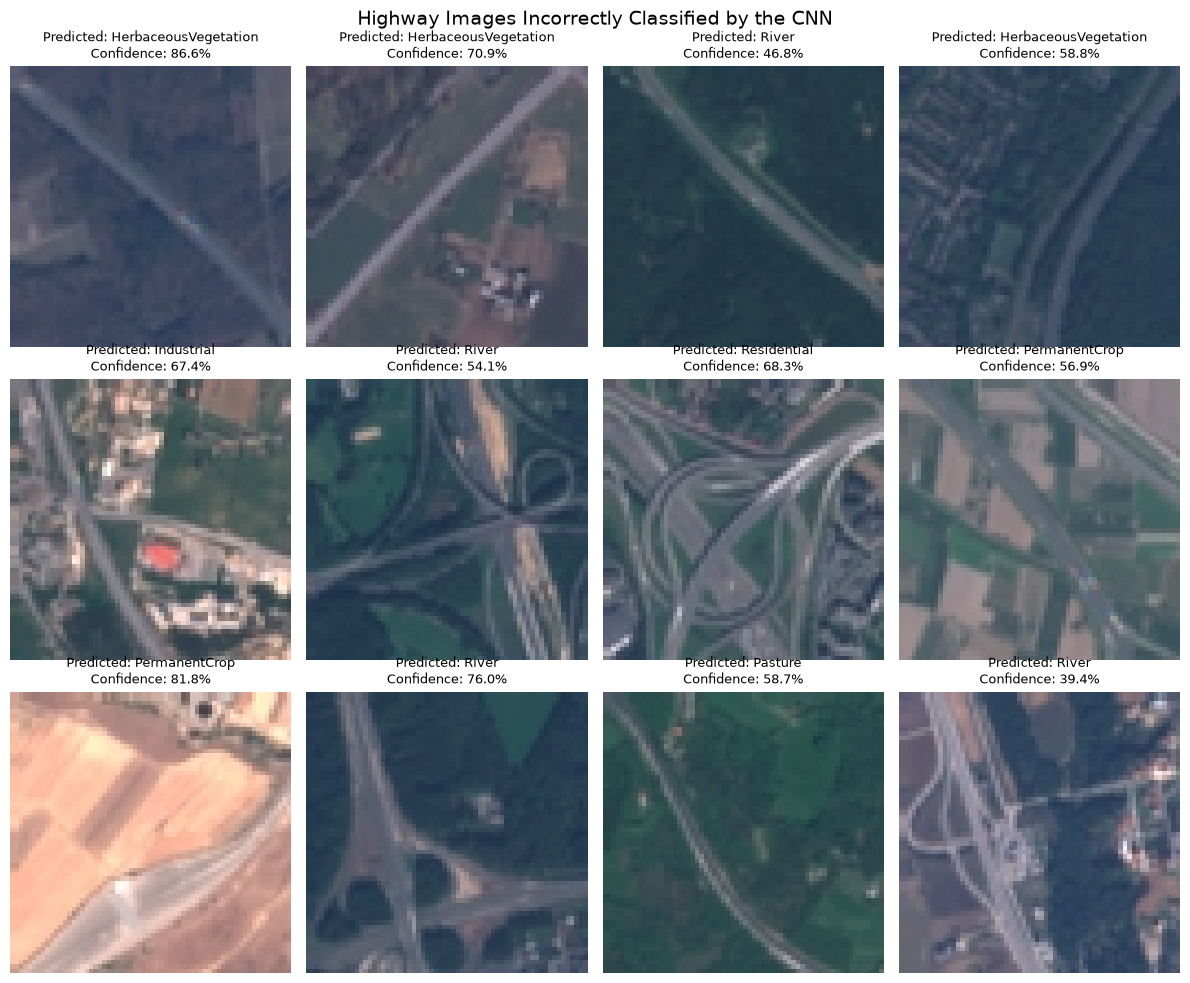

In [60]:
# Select Highway images that the model classified incorrectly.
highway_errors = misclassified[
    misclassified["category"] == "Highway"
]

# Select 12 examples using a fixed random seed.
sample_errors = highway_errors.sample(
    n=min(12, len(highway_errors)),
    random_state=42
)

fig, axes = plt.subplots(
    nrows=3,
    ncols=4,
    figsize=(12, 10)
)

for ax, (_, record) in zip(axes.flat, sample_errors.iterrows()):

    image_path = project_folder / record["image_path"]

    with Image.open(image_path) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(
        f"Predicted: {record['predicted_category']}\n"
        f"Confidence: {record['confidence']:.1%}",
        fontsize=9
    )

    ax.axis("off")

# Hide unused axes if fewer than 12 errors exist.
for ax in axes.flat[len(sample_errors):]:
    ax.axis("off")

plt.suptitle(
    "Highway Images Incorrectly Classified by the CNN",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    figures_folder / "highway_misclassifications.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

#### 10.4.1 What the Misclassified Images Revealed

Of the 4,050 test images, the CNN correctly classified **3,271** and misclassified **779**, giving an overall error rate of **19.23%**.

Highway accounted for 253 of these errors, making it the category with the largest number of missed examples.

Looking at the misclassified Highway images helped me understand some of the possible reasons. Several images contain roads surrounded by vegetation or farmland, while others show complicated intersections and nearby buildings.

This may explain why the model sometimes predicts HerbaceousVegetation, PermanentCrop or Industrial instead of Highway. Roads and rivers can also share similar narrow, elongated shapes when viewed from above, which is consistent with the 90 Highway images incorrectly classified as River.

I also noticed that some incorrect predictions received relatively high softmax scores. For example, one Highway image was classified as HerbaceousVegetation with a score of 86.6%. This shows that a model can produce a strong prediction score and still be wrong.

These observations suggest that the CNN sometimes struggles when an image contains several competing visual features. However, I cannot determine exactly which image regions influenced its decisions without further interpretability analysis.

The results highlight an important limitation of the model: recognising land-cover categories is more difficult when different visual patterns overlap within a small image.

### 10.5 Final Evaluation and Model Limitations

The final evaluation shows that the augmented CNN can recognise many EuroSAT land-use and land-cover categories reasonably well, achieving **80.77% accuracy** and a **macro F1-score of 79.42%** on the held-out test set.

The model performed particularly well on SeaLake, Forest and Residential, which achieved F1-scores above 92%. However, performance was uneven. Highway was the weakest category, with a recall of only 32.53%, while PermanentCrop also proved challenging.

The confusion matrix and visual error analysis helped explain these differences. Many mistakes occurred between categories that share colours, textures or spatial patterns. In particular, some Highway images contained roads surrounded by vegetation, farmland or buildings, making them visually complex.

The improvement experiment also produced a useful result. Adding flips and rotations increased validation accuracy from 76.42% to 79.26% and reduced validation loss from 0.6395 to 0.5714. This suggests that geometric augmentation improved generalisation under the conditions tested.

However, several limitations remain.

First, the model was trained and tested using images from the same EuroSAT dataset. Although the images were separated into different partitions, geographic independence could not be established.

Second, the experiment used a relatively small CNN trained from scratch. More advanced architectures or transfer learning might improve performance, particularly for categories such as Highway.

Third, the improvement was tested in a single training run. Repeating experiments with different random seeds would help establish whether the observed improvement is consistent.

Finally, the model's performance has only been evaluated for satellite land-cover classification. These results do not demonstrate suitability for facial recognition, premises security or other operational applications.

Overall, the investigation demonstrates both the potential of CNN-based image recognition and the importance of examining individual classification errors rather than relying on overall accuracy alone.

### 10.6 Examining Prediction Confidence

During the visual error analysis, I noticed that some incorrect predictions received relatively high softmax scores.

Guo et al. (2017) explain that neural networks can produce probabilities that do not accurately reflect how often their predictions are correct.

This made me interested in whether my CNN generally assigns higher prediction scores when it classifies an image correctly.

I'll compare the average maximum softmax scores for correct and incorrect classifications.

This is a simple investigation of prediction confidence, not a complete probability calibration assessment.

In [61]:
# Separate prediction scores for correct and incorrect classifications.
correct_predictions = test_records[
    test_records["label"] == test_records["predicted_label"]
]

incorrect_predictions = test_records[
    test_records["label"] != test_records["predicted_label"]
]

# Calculate average prediction scores.
confidence_summary = pd.DataFrame({
    "Prediction outcome": ["Correct", "Incorrect"],
    "Images": [
        len(correct_predictions),
        len(incorrect_predictions)
    ],
    "Average prediction score": [
        correct_predictions["confidence"].mean(),
        incorrect_predictions["confidence"].mean()
    ]
})

display(
    confidence_summary.style.format({
        "Average prediction score": "{:.2%}"
    })
)

,Prediction outcome,Images,Average prediction score
0,Correct,3271,83.63%
1,Incorrect,779,60.17%


#### 10.6.1 What the Prediction Scores Revealed

The confidence analysis showed that the CNN generally produced higher prediction scores when its classifications were correct.

The 3,271 correctly classified images had an average prediction score of **83.63%**, compared with **60.17%** for the 779 incorrect predictions. This is a difference of **23.46 percentage points**.

This suggests that the model's prediction scores provide some indication of reliability. However, they are not a guarantee of correctness.

During the visual error analysis, I found examples where the CNN assigned relatively high scores to incorrect predictions. One Highway image, for example, was classified as HerbaceousVegetation with a score of 86.6%.

These findings remind me that the model's output probabilities should be interpreted carefully. The analysis compares average prediction scores, but it does not establish whether those probabilities are well calibrated.

Overall, this provides another reason to evaluate the CNN using several measures rather than relying on accuracy or prediction confidence alone.

## 11. Findings and Recommendations

### 11.1 Summary of the Investigation

In this project, I developed and evaluated a Convolutional Neural Network to classify satellite images into ten land-use and land-cover categories using the EuroSAT RGB dataset.

I began by investigating the quality and characteristics of the 27,000 images using Python and Apache Spark. The analysis confirmed that all images had consistent dimensions and formats, while also revealing differences in class distribution, brightness, contrast and visual patterns.

These findings guided my preparation of the images, including stratified splitting, normalisation and the decision to retain the original 64 × 64 RGB resolution.

I then trained a compact baseline CNN containing 102,154 trainable parameters. The baseline achieved **76.42% validation accuracy**, but its training curves suggested that generalisation stopped improving after epoch 5.

To investigate this, I introduced geometric data augmentation while keeping the underlying architecture unchanged. The augmented model improved validation accuracy to **79.26%** and reduced validation loss from **0.6395 to 0.5714**.

The selected model achieved **80.77% accuracy** and a **macro F1-score of 79.42%** on the 4,050 held-out test images.

### 11.2 Key Findings

The results demonstrate that even a relatively small CNN can learn useful features for satellite image classification.

However, performance differed considerably between categories. SeaLake, Forest and Residential achieved F1-scores above 92%, while Highway remained challenging, with an F1-score of only 44.85%.

The confusion matrix and visual error analysis showed that many mistakes occurred between categories with overlapping visual patterns. In particular, Highway images were often confused with River, PermanentCrop and HerbaceousVegetation.

The experiment also showed that augmentation improved validation performance under the tested conditions, although repeated experiments would be needed to establish how consistent this improvement is.

### 11.3 Recommendations and Future Improvements

Although the results are encouraging, I would not consider the model ready for real-world deployment.

The most useful next step would be to investigate why Highway images are so difficult to classify. An interpretability method such as Grad-CAM could help reveal which parts of an image influence the CNN's predictions.

I would also consider testing transfer learning with a pretrained image-classification model, which might improve feature extraction without requiring a much larger dataset.

Repeating the experiments with different random seeds would help determine whether the improvements are consistent.

Finally, evaluating the model on geographically independent images would provide stronger evidence of its ability to generalise beyond the EuroSAT benchmark.

### 11.4 Conclusion

This investigation showed me that building a CNN is only one part of image classification. Understanding the data, checking its quality and examining the model's mistakes are just as important.

The augmented CNN achieved encouraging overall results, but the class-level evaluation revealed limitations that accuracy alone would have hidden.

By connecting the EDA findings to image preparation, training and evaluation, I was able to develop a reproducible image-classification workflow and demonstrate both the strengths and weaknesses of the final model.

## 12. References

Apache Software Foundation, 2026. *Quickstart: DataFrame*. PySpark 4.2.0 documentation. Available at: https://spark.apache.org/docs/4.2.0/api/python/getting_started/quickstart_df.html [Accessed 18 November 2026].

Google, n.d. *Data augmentation*. TensorFlow. Available at: https://www.tensorflow.org/tutorials/images/data_augmentation [Accessed 18 November 2026].

Guo, C., Pleiss, G., Sun, Y. and Weinberger, K.Q., 2017. On calibration of modern neural networks. Proceedings of the 34th International Conference on Machine Learning, 70, pp.1321–1330. Available at: https://proceedings.mlr.press/v70/guo17a.html [Accessed 18 November 2026].

Helber, P., Bischke, B., Dengel, A. and Borth, D., 2019. EuroSAT: A novel dataset and deep learning benchmark for land use and land cover classification. *IEEE Journal of Selected Topics in Applied Earth Observations and Remote Sensing*, 12(7), pp.2217–2226. Available at: https://doi.org/10.1109/JSTARS.2019.2918242 [Accessed 18 November 2026].

Helber, P., Bischke, B., Dengel, A. and Borth, D., 2023. *EuroSAT: A novel dataset and deep learning benchmark for land use and land cover classification*. [Dataset]. Zenodo. Available at: https://doi.org/10.5281/zenodo.7711810 [Accessed 18 November 2026].

Kaufman, S., Rosset, S., Perlich, C. and Stitelman, O., 2012. Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data*, 6(4), article 15. Available at: https://doi.org/10.1145/2382577.2382579 [Accessed 18 November 2026].

LeCun, Y., Bengio, Y. and Hinton, G., 2015. Deep learning. *Nature*, 521, pp.436–444. Available at: https://doi.org/10.1038/nature14539 [Accessed 18 November 2026].

Roberts, D.R. et al., 2017. Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography*, 40(8), pp.913–929. Available at: https://doi.org/10.1111/ecog.02881 [Accessed 18 November 2026].

Scikit-learn developers, n.d. *Classification report*. scikit-learn documentation. Available at: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html [Accessed 18 November 2026].

Shorten, C. and Khoshgoftaar, T.M., 2019. A survey on image data augmentation for deep learning. *Journal of Big Data*, 6, article 60. Available at: https://doi.org/10.1186/s40537-019-0197-0 [Accessed 18 November 2026].

Sokolova, M. and Lapalme, G., 2009. A systematic analysis of performance measures for classification tasks. Information Processing & Management, 45(4), pp.427–437. Available at: https://doi.org/10.1016/j.ipm.2009.03.002 [Accessed 18 November 2026].